# Laboratorio III – Deep Learning: Reconocimiento de Lenguaje de Señas ASL

Este cuaderno corresponde al tercer laboratorio del curso. Se construye y evalúa el primer prototipo del motor de reconocimiento de SignBridge, un clasificador de letras del alfabeto de Lenguaje de Señas Americano a partir de fotografías de manos. Se utiliza el conjunto ASL Alphabet de Kaggle y el objetivo es reconocer, letra por letra, la seña que hace una persona frente a la cámara.

El alcance del laboratorio abarca el análisis exploratorio del conjunto, el preprocesamiento de las imágenes, la construcción y comparación de varios modelos, redes convolucionales, una red neuronal densa y un algoritmo clásico, el efecto de la aumentación de datos, la prueba del mejor modelo con señas propias y una reflexión sobre accesibilidad y sesgo.

## Verificación de entorno

Esta sección confirma la versión de Python, las versiones de las librerías utilizadas y la existencia de las rutas del proyecto. Sirve para garantizar que el cuaderno se pueda reproducir en otra máquina.

In [71]:
import sys
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import PIL
from PIL import Image
import cv2
import sklearn
import pyarrow

print("Entorno de ejecución")
print("-" * 60)
print(f"Sistema      : {platform.system()} {platform.release()} {platform.machine()}")
print(f"Python       : {sys.version.split()[0]}")
print(f"numpy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")
print(f"seaborn      : {sns.__version__}")
print(f"pillow       : {PIL.__version__}")
print(f"opencv       : {cv2.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"pyarrow      : {pyarrow.__version__}")

Entorno de ejecución
------------------------------------------------------------
Sistema      : Windows 10 AMD64
Python       : 3.12.0
numpy        : 2.5.2
pandas       : 3.0.5
matplotlib   : 3.11.1
seaborn      : 0.13.2
pillow       : 12.3.0
opencv       : 5.0.0
scikit-learn : 1.9.0
pyarrow      : 25.0.1


## Rutas del proyecto y utilidades de figuras

Las rutas se definen una sola vez como constantes para que renombrar una carpeta sea un cambio de una sola línea. Las figuras se exportan con un contador secuencial mediante una función que devuelve nombres del tipo Figura1.png y registra un índice de número y descripción en indice_figuras.csv, lo que permite referenciarlas después desde el informe.

In [72]:
# raiz del proyecto, el cuaderno vive en notebook/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()

DIR_DATOS = RAIZ / "data"
DIR_CRUDO = DIR_DATOS / "raw"
DIR_PROCESADO = DIR_DATOS / "processed"
DIR_FIGURAS = RAIZ / "figures"

# Resuelve la ruta de cada carpeta soportando el doble anidamiento del zip de Kaggle o la forma plana
def resolver_cruda(nombre):
    candidatos = [DIR_CRUDO / nombre / nombre, DIR_CRUDO / nombre]
    for candidato in candidatos:
        if candidato.exists():
            return candidato
    return candidatos[0]

DIR_TRAIN_CRUDO = resolver_cruda("asl_alphabet_train")
DIR_TEST_CRUDO = resolver_cruda("asl_alphabet_test")

INDICE_FIGURAS = DIR_FIGURAS / "indice_figuras.csv"

DIR_PROCESADO.mkdir(parents=True, exist_ok=True)
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

print("Rutas del proyecto")
print("-" * 60)
for nombre, ruta in [
    ("raiz", RAIZ),
    ("datos crudos", DIR_CRUDO),
    ("datos procesados", DIR_PROCESADO),
    ("figuras", DIR_FIGURAS),
    ("entrenamiento crudo", DIR_TRAIN_CRUDO),
    ("prueba oficial", DIR_TEST_CRUDO),
]:
    print(f"{nombre:22s} existe={ruta.exists()}  {ruta}")

Rutas del proyecto
------------------------------------------------------------
raiz                   existe=True  c:\Users\andre\Desktop\Lab3
datos crudos           existe=True  c:\Users\andre\Desktop\Lab3\data\raw
datos procesados       existe=True  c:\Users\andre\Desktop\Lab3\data\processed
figuras                existe=True  c:\Users\andre\Desktop\Lab3\figures
entrenamiento crudo    existe=True  c:\Users\andre\Desktop\Lab3\data\raw\asl_alphabet_train
prueba oficial         existe=True  c:\Users\andre\Desktop\Lab3\data\raw\asl_alphabet_test


In [73]:
_contador_figuras = {"n": 0}


def guardar_figura(fig, descripcion):
    """Guarda la figura con numeración secuencial y registra su descripción en el índice."""
    _contador_figuras["n"] += 1
    n = _contador_figuras["n"]
    nombre = f"Figura{n}.png"
    ruta = DIR_FIGURAS / nombre
    fig.savefig(ruta, dpi=150, bbox_inches="tight", facecolor="white")

    fila = pd.DataFrame([{"numero": n, "archivo": nombre, "descripcion": descripcion}])
    if n == 1:
        fila.to_csv(INDICE_FIGURAS, index=False)
    else:
        fila.to_csv(INDICE_FIGURAS, mode="a", header=False, index=False)

    print(f"Figura {n} guardada: {nombre}")
    return ruta


SEMILLA = 42
np.random.seed(SEMILLA)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12

## Preparación e inventario del conjunto de datos

El primer paso es recorrer el árbol de carpetas y construir una tabla con una fila por imagen. De cada archivo se extrae la clase, tomada del nombre de la carpeta, y el índice numérico que aparece en el nombre del archivo. Ese índice resulta clave más adelante porque codifica el orden en que se capturaron las imágenes.

In [74]:
registros = []
for carpeta in sorted(p for p in DIR_TRAIN_CRUDO.iterdir() if p.is_dir()):
    clase = carpeta.name
    for archivo in carpeta.glob("*.jpg"):
        indice = int("".join(c for c in archivo.stem if c.isdigit()))
        registros.append({"clase": clase, "indice": indice, "archivo": archivo.name})

inventario = pd.DataFrame(registros).sort_values(["clase", "indice"]).reset_index(drop=True)

print("Inventario del conjunto de entrenamiento")
print("-" * 60)
print(f"Imágenes totales : {len(inventario):,}")
print(f"Clases distintas : {inventario['clase'].nunique()}")
print(f"Índice mínimo    : {inventario['indice'].min()}")
print(f"Índice máximo    : {inventario['indice'].max()}")
print()
print("Primeras filas del inventario")
print(inventario.head(8).to_string(index=False))

Inventario del conjunto de entrenamiento
------------------------------------------------------------
Imágenes totales : 87,000
Clases distintas : 29
Índice mínimo    : 1
Índice máximo    : 3000

Primeras filas del inventario
clase  indice archivo
    A       1  A1.jpg
    A       2  A2.jpg
    A       3  A3.jpg
    A       4  A4.jpg
    A       5  A5.jpg
    A       6  A6.jpg
    A       7  A7.jpg
    A       8  A8.jpg


In [75]:
CLASES = sorted(inventario["clase"].unique())
LETRAS = [c for c in CLASES if len(c) == 1]
ESPECIALES = [c for c in CLASES if len(c) > 1]

print("Clases del problema")
print("-" * 60)
print(f"Total de clases      : {len(CLASES)}")
print(f"Letras del alfabeto  : {len(LETRAS)}")
print(f"  {' '.join(LETRAS)}")
print(f"Clases de control    : {len(ESPECIALES)}")
print(f"  {' '.join(ESPECIALES)}")
print()
print("Las tres clases de control corresponden a espacio, borrar y ausencia de seña.")
print("Están pensadas para aplicaciones de escritura en tiempo real como la de SignBridge.")

Clases del problema
------------------------------------------------------------
Total de clases      : 29
Letras del alfabeto  : 26
  A B C D E F G H I J K L M N O P Q R S T U V W X Y Z
Clases de control    : 3
  del nothing space

Las tres clases de control corresponden a espacio, borrar y ausencia de seña.
Están pensadas para aplicaciones de escritura en tiempo real como la de SignBridge.


In [76]:
archivos_test_oficial = sorted(DIR_TEST_CRUDO.glob("*.jpg"))
clases_test_oficial = sorted(p.stem.replace("_test", "") for p in archivos_test_oficial)
faltantes = sorted(set(CLASES) - set(clases_test_oficial))

print("Conjunto de prueba oficial de Kaggle")
print("-" * 60)
print(f"Imágenes disponibles : {len(archivos_test_oficial)}")
print(f"Clases representadas : {len(clases_test_oficial)}")
print(f"Clases sin ejemplo   : {faltantes if faltantes else 'ninguna'}")
print()
print("El conjunto oficial trae una sola imagen por clase y ni siquiera cubre las 29 clases.")
print("Con 28 imágenes no es posible estimar métricas confiables, por lo que se construye")
print("un conjunto de prueba propio a partir de los datos de entrenamiento.")

Conjunto de prueba oficial de Kaggle
------------------------------------------------------------
Imágenes disponibles : 28
Clases representadas : 28
Clases sin ejemplo   : ['del']

El conjunto oficial trae una sola imagen por clase y ni siquiera cubre las 29 clases.
Con 28 imágenes no es posible estimar métricas confiables, por lo que se construye
un conjunto de prueba propio a partir de los datos de entrenamiento.


## Ejercicio 1 – Ejemplos de señas y variabilidad dentro de una misma letra

Antes de cualquier cálculo conviene mirar las imágenes. La primera figura muestra ocho letras distintas del alfabeto ASL junto a las tres clases de control, con una muestra por clase. La segunda figura toma una sola letra y muestra varias capturas separadas entre sí para observar cuánto varía una misma clase.

In [77]:
def leer_rgb(ruta, tam=None):
    """Lee una imagen en RGB y opcionalmente la redimensiona."""
    with Image.open(ruta) as im:
        im = im.convert("RGB")
        if tam is not None:
            im = im.resize(tam, Image.BILINEAR)
        return np.asarray(im)


def ruta_imagen(clase, indice):
    return DIR_TRAIN_CRUDO / clase / f"{clase}{indice}.jpg"

Figura 1 guardada: Figura1.png


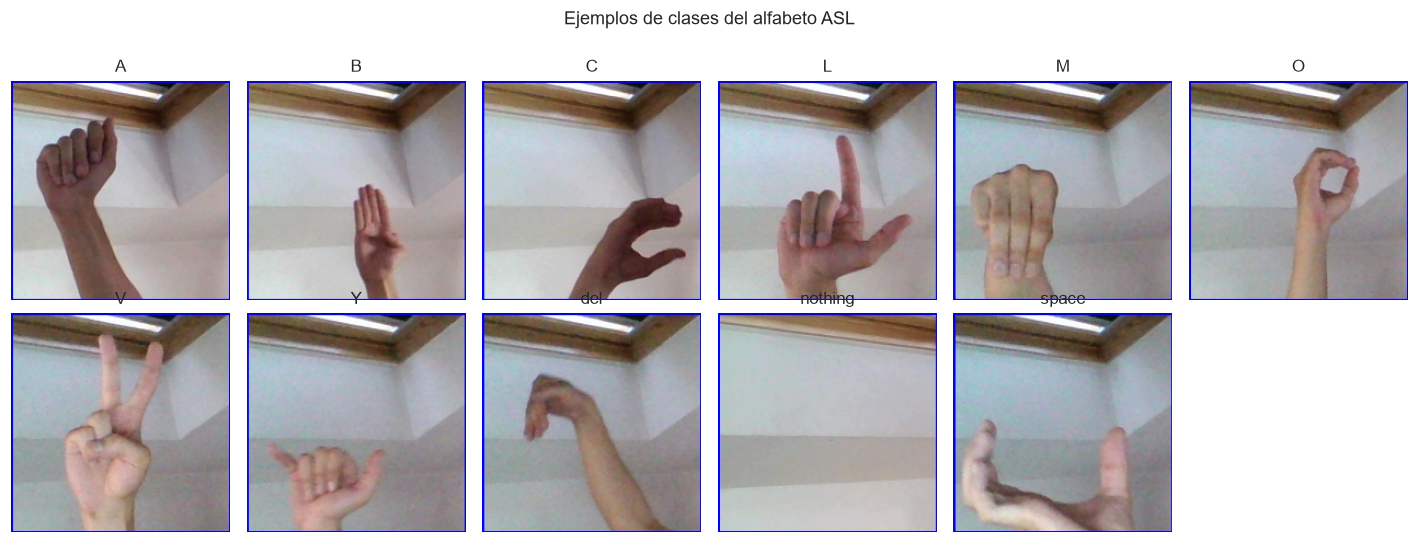

In [78]:
muestra_clases = ["A", "B", "C", "L", "M", "O", "V", "Y", "del", "nothing", "space"]

fig, ejes = plt.subplots(2, 6, figsize=(13, 4.8))
for eje, clase in zip(ejes.ravel(), muestra_clases):
    eje.imshow(leer_rgb(ruta_imagen(clase, 1500)))
    eje.set_title(clase, fontsize=11)
    eje.axis("off")
ejes.ravel()[-1].axis("off")
fig.suptitle("Ejemplos de clases del alfabeto ASL", y=1.02)
fig.tight_layout()
guardar_figura(fig, "Ejemplos de ocho letras del alfabeto ASL y las tres clases de control")
plt.show()

Figura 2 guardada: Figura2.png


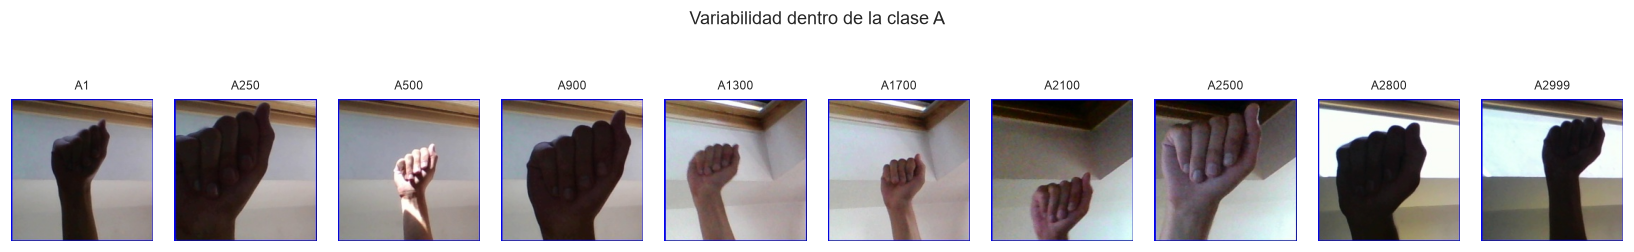

Figura 3 guardada: Figura3.png


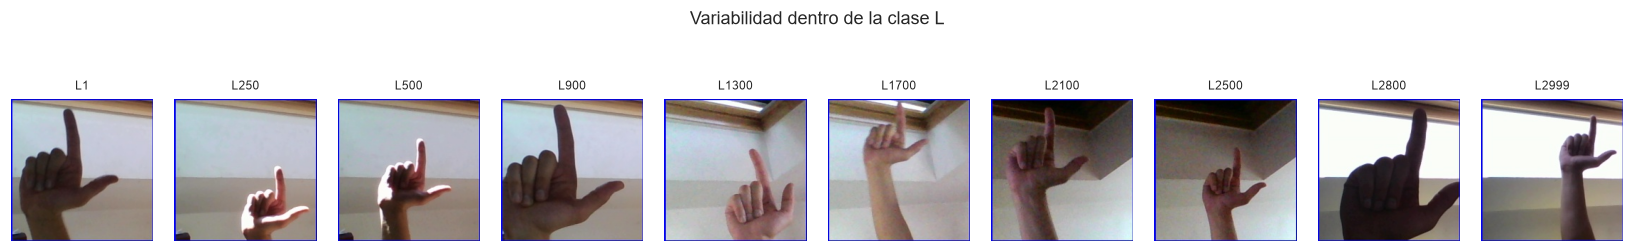

In [79]:
indices_variabilidad = [1, 250, 500, 900, 1300, 1700, 2100, 2500, 2800, 2999]

for clase in ["A", "L"]:
    fig, ejes = plt.subplots(1, len(indices_variabilidad), figsize=(15, 1.9))
    for eje, i in zip(ejes, indices_variabilidad):
        eje.imshow(leer_rgb(ruta_imagen(clase, i)))
        eje.set_title(f"{clase}{i}", fontsize=8)
        eje.axis("off")
    fig.suptitle(f"Variabilidad dentro de la clase {clase}", y=1.18)
    fig.tight_layout()
    guardar_figura(fig, f"Diez capturas separadas de la letra {clase} que muestran la variabilidad dentro de la clase")
    plt.show()

Las capturas de una misma letra mantienen la pose de la mano pero cambian de forma notable en iluminación, distancia a la cámara, encuadre y ángulo de la muñeca. En algunas imágenes la mano aparece casi en silueta por contraluz y en otras aparece completamente iluminada. Esa es la variabilidad que el modelo tendrá que absorber.

También se observa algo que condiciona todo el trabajo, todas las imágenes fueron capturadas por una misma persona, con la misma mano y en el mismo ambiente, una esquina de habitación con una moldura de madera al fondo. Ese punto se retoma en la sección de accesibilidad y sesgo.

## Ejercicio 2 – Análisis exploratorio del conjunto

Se realiza un análisis exploratorio para entender el conjunto antes de modelar. Se revisan las propiedades técnicas de las imágenes, la distribución de clases, las condiciones de captura, la estructura secuencial de los fotogramas, la construcción de los conjuntos de entrenamiento, validación y prueba, la evidencia empírica de la fuga de información y la similitud visual entre letras.

### Propiedades técnicas de las imágenes

Se verifica el formato, la resolución y el modo de color sobre una muestra amplia para confirmar que el conjunto es homogéneo y que no hay archivos corruptos.

In [80]:
muestra_tecnica = inventario.groupby("clase", group_keys=False).sample(30, random_state=SEMILLA)

propiedades = []
for _, fila in muestra_tecnica.iterrows():
    ruta = ruta_imagen(fila["clase"], fila["indice"])
    with Image.open(ruta) as im:
        propiedades.append({
            "clase": fila["clase"],
            "formato": im.format,
            "modo": im.mode,
            "ancho": im.size[0],
            "alto": im.size[1],
            "peso_kb": ruta.stat().st_size / 1024,
        })

propiedades = pd.DataFrame(propiedades)

print("Propiedades técnicas sobre una muestra de 30 imágenes por clase")
print("-" * 60)
print(f"Imágenes inspeccionadas : {len(propiedades)}")
print(f"Formatos encontrados    : {propiedades['formato'].unique().tolist()}")
print(f"Modos de color          : {propiedades['modo'].unique().tolist()}")
print(f"Resoluciones            : {propiedades[['ancho', 'alto']].drop_duplicates().values.tolist()}")
print(f"Peso medio por archivo  : {propiedades['peso_kb'].mean():.1f} KB")
print(f"Peso mínimo y máximo    : {propiedades['peso_kb'].min():.1f} KB y {propiedades['peso_kb'].max():.1f} KB")

Propiedades técnicas sobre una muestra de 30 imágenes por clase
------------------------------------------------------------
Imágenes inspeccionadas : 870
Formatos encontrados    : ['JPEG']
Modos de color          : ['RGB']
Resoluciones            : [[200, 200]]
Peso medio por archivo  : 12.4 KB
Peso mínimo y máximo    : 8.7 KB y 15.4 KB


In [81]:
pixeles_por_imagen = 200 * 200 * 3
bytes_totales_crudo = len(inventario) * pixeles_por_imagen

print("Costo de cargar el conjunto completo en memoria")
print("-" * 60)
print(f"Píxeles por imagen a 200x200 RGB : {pixeles_por_imagen:,}")
print(f"Imágenes totales                 : {len(inventario):,}")
print(f"Memoria como entero de 8 bits    : {bytes_totales_crudo / 1024**3:.2f} GB")
print(f"Memoria como flotante de 32 bits : {bytes_totales_crudo * 4 / 1024**3:.2f} GB")
print()
print("Cargar todo a resolución original en flotante supera la memoria disponible en un equipo")
print("de laboratorio, lo que justifica la submuestra y la reducción de resolución.")

Costo de cargar el conjunto completo en memoria
------------------------------------------------------------
Píxeles por imagen a 200x200 RGB : 120,000
Imágenes totales                 : 87,000
Memoria como entero de 8 bits    : 9.72 GB
Memoria como flotante de 32 bits : 38.89 GB

Cargar todo a resolución original en flotante supera la memoria disponible en un equipo
de laboratorio, lo que justifica la submuestra y la reducción de resolución.


El conjunto es completamente homogéneo, todas las imágenes son JPEG de 200 por 200 píxeles en modo RGB, sin archivos corruptos ni resoluciones mezcladas. Eso simplifica el preprocesamiento porque no hace falta manejar tamaños variables ni imágenes en escala de grises.

El costo de memoria confirma la advertencia del enunciado. Las 87,000 imágenes a resolución original ocupan alrededor de 9.7 GB en flotante de 32 bits, muy por encima de lo manejable, por lo que se trabaja con una submuestra por clase y a resolución reducida.

### Distribución de clases

Se revisa cuántas imágenes hay por clase para determinar si el conjunto está balanceado, algo que define si la exactitud es una métrica razonable o si hay que recurrir a métricas por clase.

Figura 4 guardada: Figura4.png


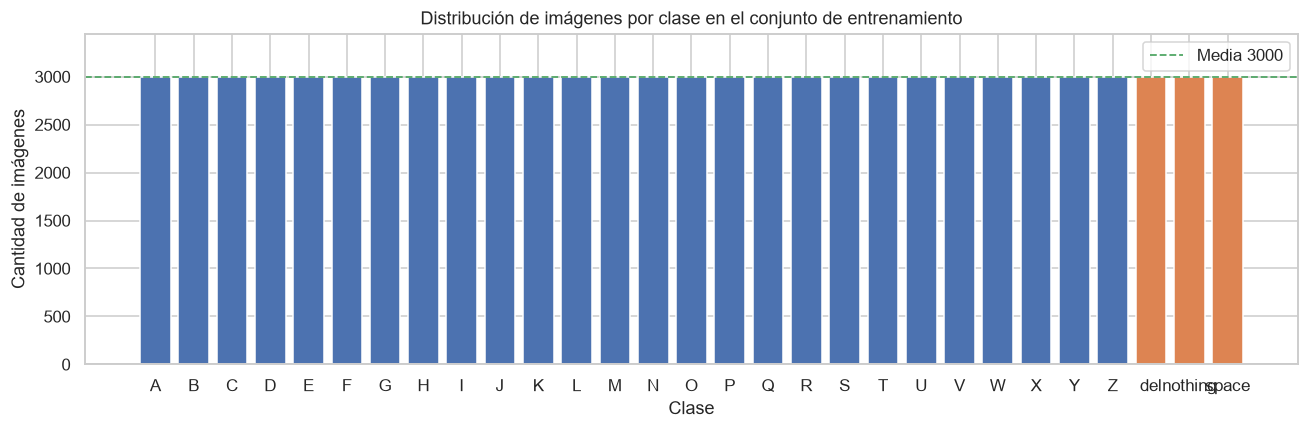

Balance del conjunto
------------------------------------------------------------
Mínimo por clase   : 3,000
Máximo por clase   : 3,000
Desviación estándar: 0.00
Razón máximo sobre mínimo: 1.00


In [82]:
conteos = inventario["clase"].value_counts().sort_index()

fig, eje = plt.subplots(figsize=(12, 4))
colores = ["#4C72B0" if len(c) == 1 else "#DD8452" for c in conteos.index]
eje.bar(conteos.index, conteos.values, color=colores)
eje.set_xlabel("Clase")
eje.set_ylabel("Cantidad de imágenes")
eje.set_title("Distribución de imágenes por clase en el conjunto de entrenamiento")
eje.set_ylim(0, conteos.max() * 1.15)
eje.axhline(conteos.mean(), color="#55A868", linestyle="--", linewidth=1.2, label=f"Media {conteos.mean():.0f}")
eje.legend()
fig.tight_layout()
guardar_figura(fig, "Distribución de imágenes por clase en el conjunto de entrenamiento original")
plt.show()

print("Balance del conjunto")
print("-" * 60)
print(f"Mínimo por clase   : {conteos.min():,}")
print(f"Máximo por clase   : {conteos.max():,}")
print(f"Desviación estándar: {conteos.std():.2f}")
print(f"Razón máximo sobre mínimo: {conteos.max() / conteos.min():.2f}")

El conjunto está perfectamente balanceado, las 29 clases tienen exactamente 3,000 imágenes cada una y la desviación estándar entre clases es cero. Esto es consecuencia del diseño del dataset, que fue grabado de forma controlada clase por clase y no recolectado de forma natural.

El balance tiene dos implicaciones prácticas. La exactitud global es una métrica válida porque no hay una clase mayoritaria que la infle, y la línea base de un clasificador aleatorio es 1 entre 29, es decir 3.45 por ciento. Cualquier modelo debe superar ese valor de forma clara. Al mismo tiempo, este balance perfecto es artificial, en un uso real de SignBridge las letras del español o del inglés no aparecen con la misma frecuencia, por lo que el balance del conjunto no refleja la distribución de uso del producto.

### Condiciones de captura, brillo, contraste y color

Las fotografías fueron tomadas con luz ambiente variable. Esta sección cuantifica el brillo, el contraste y la composición de color por clase para detectar si alguna clase se distingue por sus condiciones de captura y no por la pose de la mano, lo que sería un atajo indeseable para el modelo.

In [83]:
N_MUESTRA_ESTADISTICAS = 60

filas_estadisticas = []
for clase in CLASES:
    indices = inventario.loc[inventario["clase"] == clase, "indice"].sample(
        N_MUESTRA_ESTADISTICAS, random_state=SEMILLA
    )
    for i in indices:
        img = leer_rgb(ruta_imagen(clase, i), (64, 64)).astype(np.float32)
        gris = img.mean(axis=2)
        filas_estadisticas.append({
            "clase": clase,
            "brillo": gris.mean(),
            "contraste": gris.std(),
            "rojo": img[:, :, 0].mean(),
            "verde": img[:, :, 1].mean(),
            "azul": img[:, :, 2].mean(),
        })

estadisticas = pd.DataFrame(filas_estadisticas)

resumen_estadisticas = estadisticas.groupby("clase").agg(
    brillo_medio=("brillo", "mean"),
    brillo_sd=("brillo", "std"),
    contraste_medio=("contraste", "mean"),
).round(2)

print("Estadísticas de captura por clase, muestra de 60 imágenes por clase")
print("-" * 60)
print(resumen_estadisticas.to_string())

Estadísticas de captura por clase, muestra de 60 imágenes por clase
------------------------------------------------------------
         brillo_medio  brillo_sd  contraste_medio
clase                                            
A          124.639999  22.280001        60.310001
B          127.900002  19.760000        59.180000
C          135.289993  14.180000        56.660000
D          136.970001  15.720000        55.080002
E          126.290001  21.020000        59.590000
F          129.119995  19.990000        55.529999
G          117.459999  24.469999        54.730000
H          121.779999  20.719999        53.930000
I          129.529999  16.540001        55.330002
J          125.139999  20.799999        53.619999
K          131.830002  20.110001        53.830002
L          139.490005  17.920000        56.860001
M          130.309998  20.049999        55.520000
N          126.400002  21.049999        52.970001
O          141.440002  14.440000        51.119999
P          131.110001

Figura 5 guardada: Figura5.png


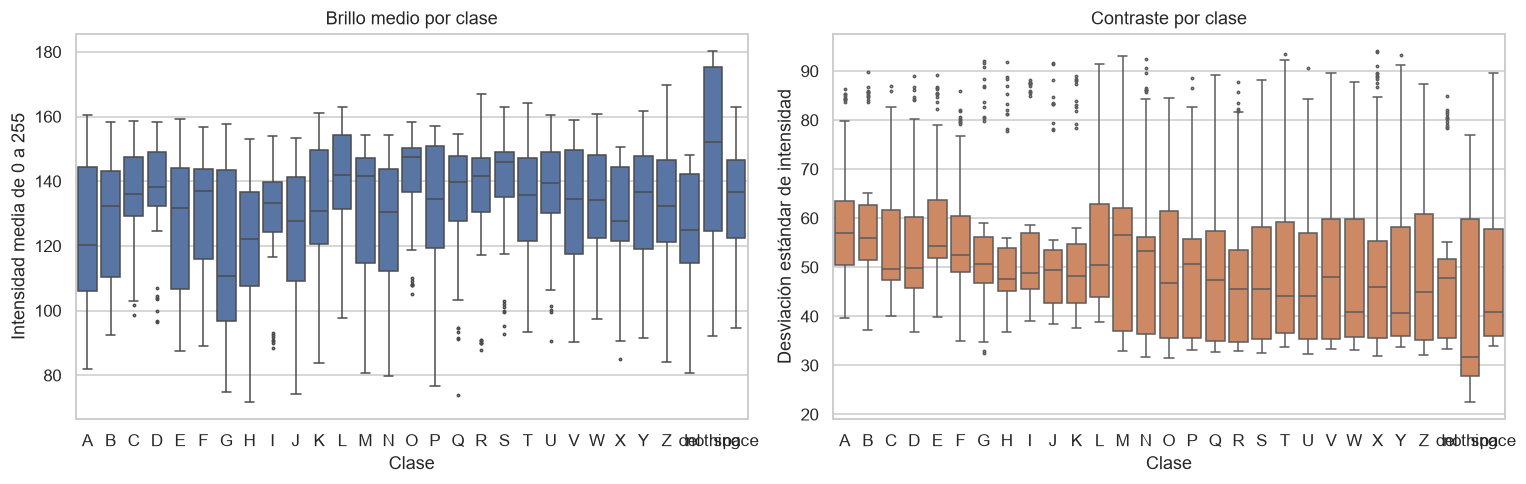

In [84]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.boxplot(data=estadisticas, x="clase", y="brillo", ax=ejes[0], color="#4C72B0", fliersize=1.5)
ejes[0].set_title("Brillo medio por clase")
ejes[0].set_xlabel("Clase")
ejes[0].set_ylabel("Intensidad media de 0 a 255")

sns.boxplot(data=estadisticas, x="clase", y="contraste", ax=ejes[1], color="#DD8452", fliersize=1.5)
ejes[1].set_title("Contraste por clase")
ejes[1].set_xlabel("Clase")
ejes[1].set_ylabel("Desviación estándar de intensidad")

fig.tight_layout()
guardar_figura(fig, "Distribución de brillo y contraste por clase")
plt.show()

Figura 6 guardada: Figura6.png


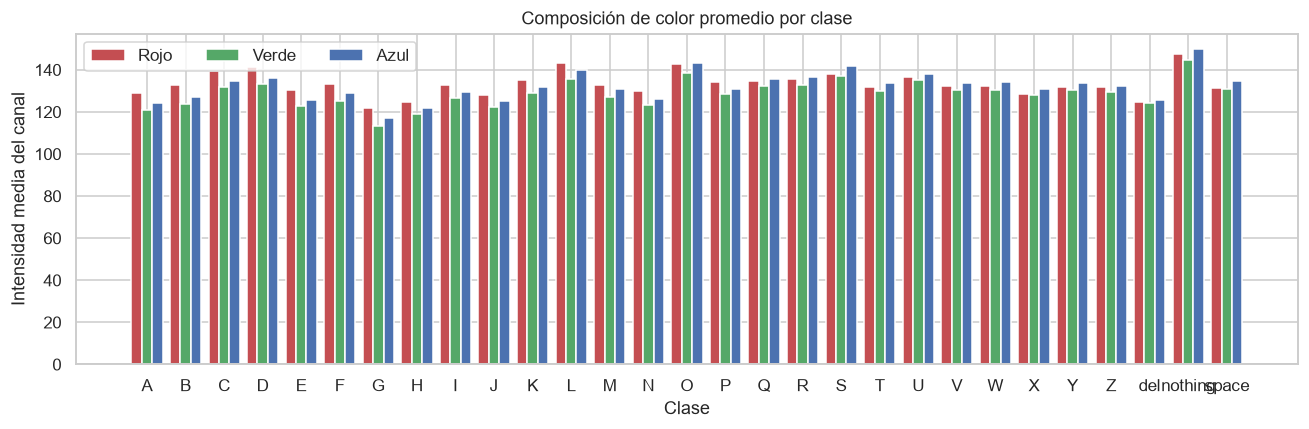

Rango de brillo entre clases
------------------------------------------------------------
Clase más oscura : G con 117.5
Clase más clara  : nothing con 147.4
Diferencia entre clases          : 29.9
Variación media dentro de clase  : 19.2


In [85]:
canales = estadisticas.groupby("clase")[["rojo", "verde", "azul"]].mean()

fig, eje = plt.subplots(figsize=(12, 4))
x = np.arange(len(canales))
ancho = 0.27
eje.bar(x - ancho, canales["rojo"], ancho, label="Rojo", color="#C44E52")
eje.bar(x, canales["verde"], ancho, label="Verde", color="#55A868")
eje.bar(x + ancho, canales["azul"], ancho, label="Azul", color="#4C72B0")
eje.set_xticks(x)
eje.set_xticklabels(canales.index)
eje.set_xlabel("Clase")
eje.set_ylabel("Intensidad media del canal")
eje.set_title("Composición de color promedio por clase")
eje.legend(ncol=3)
fig.tight_layout()
guardar_figura(fig, "Composición de color promedio por canal para cada clase")
plt.show()

print("Rango de brillo entre clases")
print("-" * 60)
print(f"Clase más oscura : {resumen_estadisticas['brillo_medio'].idxmin()} con {resumen_estadisticas['brillo_medio'].min():.1f}")
print(f"Clase más clara  : {resumen_estadisticas['brillo_medio'].idxmax()} con {resumen_estadisticas['brillo_medio'].max():.1f}")
print(f"Diferencia entre clases          : {resumen_estadisticas['brillo_medio'].max() - resumen_estadisticas['brillo_medio'].min():.1f}")
print(f"Variación media dentro de clase  : {resumen_estadisticas['brillo_sd'].mean():.1f}")

La variación de brillo dentro de una misma clase es mayor que la variación entre clases. La diferencia entre la clase más oscura y la más clara ronda los 29 niveles de intensidad, mientras que la desviación estándar del brillo dentro de una clase típica ronda los 20 niveles. Esto es una buena noticia, ninguna clase se puede identificar solo por lo clara u oscura que es la foto, así que el modelo está obligado a aprender la forma de la mano.

La clase nothing es la excepción parcial, tiene el contraste más bajo de todas, cercano a 43 frente a un promedio general por encima de 50. Tiene sentido porque en esas imágenes solo aparece la pared de fondo, sin la mano que introduce bordes y sombras. Ese contraste bajo es una pista legítima, la ausencia de mano es justamente lo que define a la clase.

En cuanto al color, los tres canales siguen el mismo patrón en todas las clases, con el rojo por encima del verde y el azul, lo que corresponde al tono de piel del firmante y a la iluminación cálida del ambiente. La composición de color es prácticamente idéntica entre clases, por lo que el color por sí solo no separa las señas.

### Estructura secuencial de las imágenes

Al mirar los nombres de archivo se observa que cada clase tiene imágenes numeradas del 1 al 3000. La pregunta que surge es si esa numeración es arbitraria o si codifica un orden de captura. La respuesta cambia por completo la forma correcta de partir los datos, por lo que se mide directamente cuánto se parecen dos imágenes en función de la distancia entre sus índices.

In [86]:
def similitud(clase, i, j):
    """Devuelve error absoluto medio y correlación entre dos imágenes de la misma clase."""
    a = leer_rgb(ruta_imagen(clase, i)).astype(np.float32)
    b = leer_rgb(ruta_imagen(clase, j)).astype(np.float32)
    return np.abs(a - b).mean(), np.corrcoef(a.ravel(), b.ravel())[0, 1]


distancias = [1, 2, 5, 10, 25, 50, 100, 250, 500, 1000, 2000]
clases_prueba = ["A", "E", "M", "R", "space"]

filas_sec = []
for clase in clases_prueba:
    for d in distancias:
        base = 100
        mae, corr = similitud(clase, base, base + d)
        filas_sec.append({"clase": clase, "distancia": d, "mae": mae, "correlacion": corr})

secuencial = pd.DataFrame(filas_sec)
tabla_sec = secuencial.groupby("distancia").agg(
    mae_medio=("mae", "mean"), correlacion_media=("correlacion", "mean")
).round(3)

print("Similitud entre pares de imágenes según la distancia entre sus índices")
print("-" * 60)
print("Promedio sobre las clases " + ", ".join(clases_prueba))
print()
print(tabla_sec.to_string())

Similitud entre pares de imágenes según la distancia entre sus índices
------------------------------------------------------------
Promedio sobre las clases A, E, M, R, space

           mae_medio  correlacion_media
distancia                              
1           3.614000              0.981
2           5.270000              0.956
5           8.206000              0.905
10         10.761000              0.858
25         10.886000              0.871
50         30.743999              0.543
100        32.243999              0.576
250        26.035999              0.646
500        29.608999              0.558
1000       52.812000              0.264
2000       71.609001              0.058


Figura 7 guardada: Figura7.png


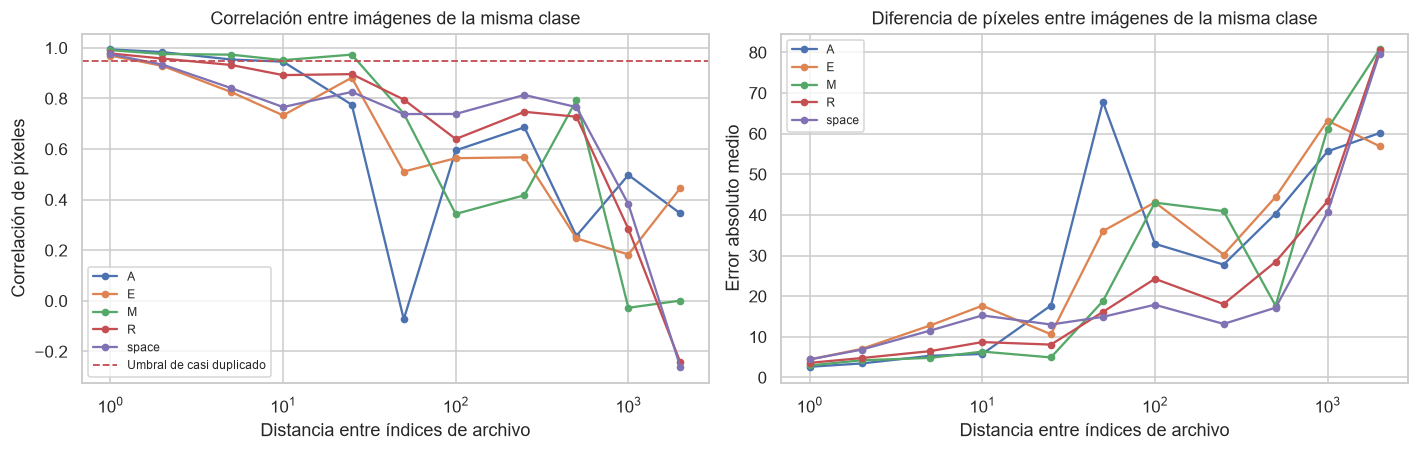

In [87]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))

for clase in clases_prueba:
    sub = secuencial[secuencial["clase"] == clase]
    ejes[0].plot(sub["distancia"], sub["correlacion"], marker="o", markersize=4, label=clase)
    ejes[1].plot(sub["distancia"], sub["mae"], marker="o", markersize=4, label=clase)

ejes[0].set_xscale("log")
ejes[0].set_xlabel("Distancia entre índices de archivo")
ejes[0].set_ylabel("Correlación de píxeles")
ejes[0].set_title("Correlación entre imágenes de la misma clase")
ejes[0].axhline(0.95, color="#C44E52", linestyle="--", linewidth=1.2, label="Umbral de casi duplicado")
ejes[0].legend(fontsize=8)

ejes[1].set_xscale("log")
ejes[1].set_xlabel("Distancia entre índices de archivo")
ejes[1].set_ylabel("Error absoluto medio")
ejes[1].set_title("Diferencia de píxeles entre imágenes de la misma clase")
ejes[1].legend(fontsize=8)

fig.tight_layout()
guardar_figura(fig, "Similitud entre imágenes de una misma clase en función de la distancia entre sus índices de archivo")
plt.show()

Figura 8 guardada: Figura8.png


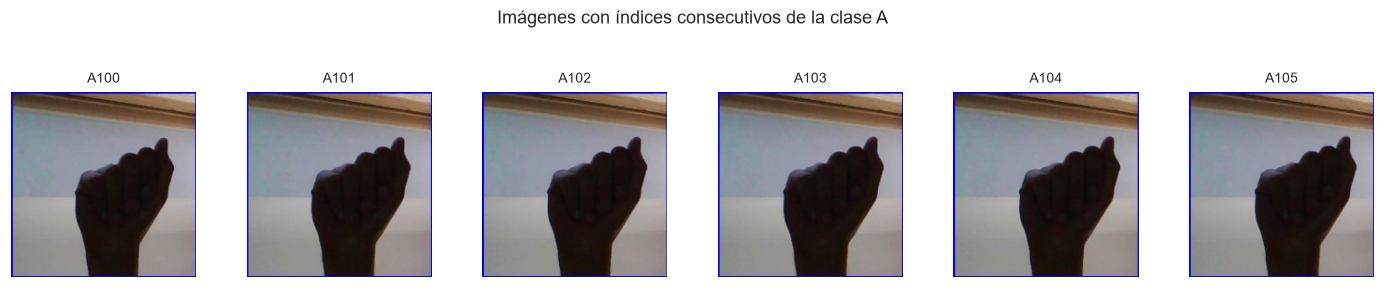

In [88]:
clase_demo = "A"
indices_demo = [100, 101, 102, 103, 104, 105]

fig, ejes = plt.subplots(1, len(indices_demo), figsize=(13, 2.3))
for eje, i in zip(ejes, indices_demo):
    eje.imshow(leer_rgb(ruta_imagen(clase_demo, i)))
    eje.set_title(f"{clase_demo}{i}", fontsize=9)
    eje.axis("off")
fig.suptitle("Imágenes con índices consecutivos de la clase A", y=1.12)
fig.tight_layout()
guardar_figura(fig, "Seis imágenes con índices consecutivos que evidencian que son fotogramas contiguos de un mismo video")
plt.show()

Este es el hallazgo más importante del análisis exploratorio. Las imágenes con índices consecutivos tienen una correlación de píxeles promedio de 0.98 y un error absoluto medio de apenas 3.6 niveles sobre 255, es decir son prácticamente la misma imagen. La similitud desciende conforme aumenta la distancia entre índices, se mantiene por encima de 0.85 hasta unas 25 posiciones y solo cae por debajo de 0.6 a partir de unas 50 posiciones.

El descenso no es perfectamente monótono, a distancias intermedias de entre 100 y 500 posiciones la correlación repunta un poco. Eso es coherente con una grabación en la que las condiciones de luz oscilan y ciertos tramos vuelven a parecerse entre sí, y refuerza que la unidad de información no es la imagen individual sino el tramo de grabación.

La conclusión es que el conjunto no está formado por 3,000 fotografías independientes por clase, sino por fotogramas extraídos de una grabación continua de video en la que la persona sostiene la seña mientras la cámara y la iluminación cambian lentamente. El número de muestras verdaderamente independientes es mucho menor que 3,000 por clase.

Esto tiene una consecuencia directa y grave sobre el diseño del experimento. Si los datos se parten de forma aleatoria, la imagen A100 puede quedar en entrenamiento y la imagen A101, que es casi idéntica, puede quedar en prueba. El modelo no estaría generalizando, estaría reconociendo una imagen que ya vio. La métrica resultante sería optimista y no diría nada sobre el desempeño real frente a una mano nueva. La siguiente sección define la partición que evita ese problema y la que le sigue mide el efecto en lugar de solo afirmarlo.

### Construcción de los conjuntos de entrenamiento, validación y prueba

A partir de los hallazgos anteriores se define una partición que evita la fuga de información entre fotogramas vecinos y a la vez reparte de forma justa las condiciones de iluminación entre los tres conjuntos.

El procedimiento es el siguiente. Para cada clase, los índices del 1 al 3000 se dividen en 30 bloques contiguos de 100 fotogramas. Cada bloque se asigna completo a uno de los tres conjuntos, nunca se parte un bloque. La asignación se sortea una sola vez con semilla fija y se aplica igual a todas las clases, lo que mantiene la comparabilidad entre clases y la reproducibilidad del experimento. Se reservan 21 bloques para entrenamiento, 4 para validación y 5 para prueba.

Asignar bloques al azar en lugar de cortar por un único punto es importante. Como la iluminación cambia de forma progresiva a lo largo de la grabación, cortar en un solo punto dejaría todas las tomas oscuras en un conjunto y todas las claras en otro, y estaríamos midiendo robustez a un cambio de iluminación en lugar de capacidad de reconocer la seña. Repartir bloques dispersos da a los tres conjuntos una mezcla comparable de condiciones sin que ningún par de fotogramas vecinos quede repartido entre conjuntos.

Queda un detalle que hay que resolver. Dos bloques contiguos asignados a conjuntos distintos siguen siendo vecinos en su frontera, por lo que el último fotograma de uno y el primero del siguiente son casi idénticos aunque pertenezcan a conjuntos diferentes. Para eliminar ese caso se descartan los 25 fotogramas de cada extremo de todos los bloques, lo que deja una banda de guarda de 50 posiciones entre cualquier par de imágenes de conjuntos distintos. A esa distancia la correlación medida en la sección anterior ya cae por debajo de 0.6, lejos del rango de casi duplicado.

Finalmente, dentro de la zona útil de cada bloque se toma una submuestra uniformemente espaciada hasta llegar a 600 imágenes por clase, valor que queda dentro del rango de 500 a 800 recomendado por el enunciado. Eso da 420 imágenes de entrenamiento, 90 de validación y 90 de prueba por clase, es decir 17,400 imágenes en total en lugar de 87,000.

In [89]:
TAM_BLOQUE = 100
MARGEN_BLOQUE = 25
N_BLOQUES = 3000 // TAM_BLOQUE
BLOQUES_TRAIN, BLOQUES_VAL, BLOQUES_TEST = 21, 4, 5
POR_CLASE = 600
POR_CLASE_TRAIN, POR_CLASE_VAL, POR_CLASE_TEST = 420, 90, 90

sorteo = np.random.default_rng(SEMILLA).permutation(N_BLOQUES)
asignacion = {}
for b in sorteo[:BLOQUES_TRAIN]:
    asignacion[int(b)] = "train"
for b in sorteo[BLOQUES_TRAIN:BLOQUES_TRAIN + BLOQUES_VAL]:
    asignacion[int(b)] = "val"
for b in sorteo[BLOQUES_TRAIN + BLOQUES_VAL:]:
    asignacion[int(b)] = "test"

print("Asignación de bloques contiguos a cada conjunto")
print("-" * 60)
for conjunto in ["train", "val", "test"]:
    bloques = sorted(b for b, c in asignacion.items() if c == conjunto)
    rangos = [f"{b * TAM_BLOQUE + 1}-{(b + 1) * TAM_BLOQUE}" for b in bloques]
    print(f"{conjunto:6s} {len(bloques):2d} bloques")
    print(f"       índices {', '.join(rangos)}")
    print()

Asignación de bloques contiguos a cada conjunto
------------------------------------------------------------
train  21 bloques
       índices 1-100, 301-400, 501-600, 601-700, 701-800, 901-1000, 1001-1100, 1201-1300, 1501-1600, 1601-1700, 1701-1800, 1801-1900, 1901-2000, 2001-2100, 2101-2200, 2201-2300, 2301-2400, 2401-2500, 2501-2600, 2601-2700, 2901-3000

val     4 bloques
       índices 201-300, 1101-1200, 1401-1500, 2801-2900

test    5 bloques
       índices 101-200, 401-500, 801-900, 1301-1400, 2701-2800



In [90]:
inventario["bloque"] = (inventario["indice"] - 1) // TAM_BLOQUE
inventario["conjunto"] = inventario["bloque"].map(asignacion)

# posicion del fotograma dentro de su bloque, se usa para aplicar la banda de guarda
inventario["posicion"] = (inventario["indice"] - 1) % TAM_BLOQUE
inventario["util"] = inventario["posicion"].between(MARGEN_BLOQUE, TAM_BLOQUE - 1 - MARGEN_BLOQUE)

objetivos = {"train": POR_CLASE_TRAIN, "val": POR_CLASE_VAL, "test": POR_CLASE_TEST}

seleccionadas = []
for clase in CLASES:
    for conjunto, objetivo in objetivos.items():
        sub = inventario[
            (inventario["clase"] == clase)
            & (inventario["conjunto"] == conjunto)
            & inventario["util"]
        ].sort_values("indice")
        # muestreo uniformemente espaciado dentro de la zona util de los bloques asignados
        posiciones = np.linspace(0, len(sub) - 1, objetivo).astype(int)
        seleccionadas.append(sub.iloc[posiciones])

particion = pd.concat(seleccionadas).reset_index(drop=True)

print("Conjuntos definidos")
print("-" * 60)
print(particion.groupby(["conjunto", "clase"]).size().unstack(0).describe().loc[["min", "max"]].to_string())
print()
resumen_particion = particion["conjunto"].value_counts().reindex(["train", "val", "test"])
for conjunto, n in resumen_particion.items():
    print(f"{conjunto:6s} {n:6,d} imágenes  {n / len(particion) * 100:5.1f} por ciento  {n // len(CLASES)} por clase")
print(f"{'total':6s} {len(particion):6,d} imágenes")

Conjuntos definidos
------------------------------------------------------------
conjunto  test  train   val
min       90.0  420.0  90.0
max       90.0  420.0  90.0

train  12,180 imágenes   70.0 por ciento  420 por clase
val     2,610 imágenes   15.0 por ciento  90 por clase
test    2,610 imágenes   15.0 por ciento  90 por clase
total  17,400 imágenes


In [91]:
solapamiento = (
    particion.groupby(["clase", "bloque"])["conjunto"].nunique().max()
)
print("Verificación de ausencia de fuga entre conjuntos")
print("-" * 60)
print(f"Máximo de conjuntos distintos que comparten un mismo bloque: {solapamiento}")
print("Un valor de 1 confirma que ningún bloque de fotogramas contiguos se reparte entre conjuntos.")
print()

distancia_minima = []
for clase in CLASES:
    tr = particion.loc[(particion["clase"] == clase) & (particion["conjunto"] == "train"), "indice"].values
    te = particion.loc[(particion["clase"] == clase) & (particion["conjunto"] == "test"), "indice"].values
    distancia_minima.append(np.abs(tr[:, None] - te[None, :]).min())

print(f"Distancia mínima de índices entre entrenamiento y prueba: {min(distancia_minima)}")
print(f"Banda de guarda impuesta por el margen de bloque       : {2 * MARGEN_BLOQUE}")
print("A esa distancia la correlación entre imágenes cae por debajo de 0.6, fuera del rango de casi duplicado.")

Verificación de ausencia de fuga entre conjuntos
------------------------------------------------------------
Máximo de conjuntos distintos que comparten un mismo bloque: 1
Un valor de 1 confirma que ningún bloque de fotogramas contiguos se reparte entre conjuntos.

Distancia mínima de índices entre entrenamiento y prueba: 52
Banda de guarda impuesta por el margen de bloque       : 50
A esa distancia la correlación entre imágenes cae por debajo de 0.6, fuera del rango de casi duplicado.


Figura 9 guardada: Figura9.png


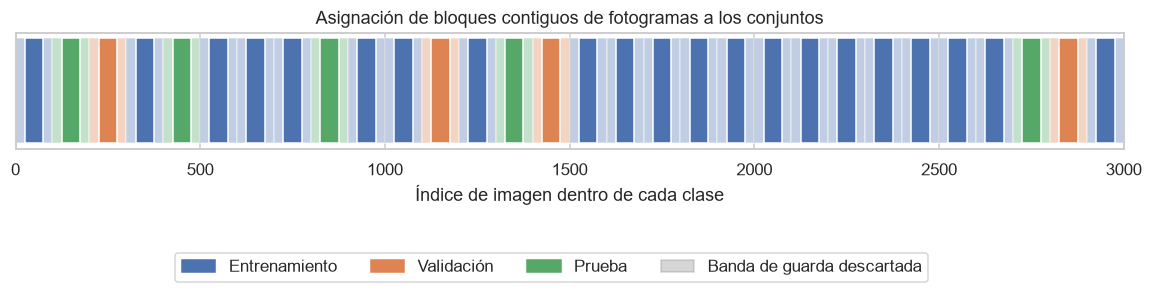

In [92]:
fig, eje = plt.subplots(figsize=(13, 3.0))
colores_conjunto = {"train": "#4C72B0", "val": "#DD8452", "test": "#55A868"}
for b in range(N_BLOQUES):
    eje.barh(0, TAM_BLOQUE, left=b * TAM_BLOQUE, height=0.6,
             color=colores_conjunto[asignacion[b]], alpha=0.35, edgecolor="white", linewidth=1.2)
    # zona util del bloque una vez descartada la banda de guarda
    eje.barh(0, TAM_BLOQUE - 2 * MARGEN_BLOQUE, left=b * TAM_BLOQUE + MARGEN_BLOQUE, height=0.6,
             color=colores_conjunto[asignacion[b]])
eje.set_yticks([])
eje.set_xlim(0, 3000)
eje.set_xlabel("Índice de imagen dentro de cada clase")
eje.set_title("Asignación de bloques contiguos de fotogramas a los conjuntos")
manijas = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colores_conjunto.values()]
manijas.append(plt.Rectangle((0, 0), 1, 1, color="#8C8C8C", alpha=0.35))
fig.legend(manijas, ["Entrenamiento", "Validación", "Prueba", "Banda de guarda descartada"],
           ncol=4, loc="lower center", bbox_to_anchor=(0.5, 0.02))
fig.subplots_adjust(top=0.80, bottom=0.45)
guardar_figura(fig, "Asignación de bloques contiguos de fotogramas a los conjuntos, con la banda de guarda descartada en cada extremo de bloque")
plt.show()

### Evidencia empírica de la fuga de información

Para confirmar el problema se compara el desempeño de un mismo clasificador sencillo, un vecino más cercano sobre imágenes reducidas a 32 por 32 en escala de grises, bajo dos particiones distintas de exactamente las mismas imágenes.

La primera es la partición por bloques que se acaba de definir. La segunda toma ese mismo conjunto de 17,400 imágenes y lo reparte al azar en las mismas proporciones, ignorando el origen secuencial de los fotogramas. Como el clasificador, las imágenes y los tamaños de cada conjunto son idénticos en ambos casos, cualquier diferencia de exactitud se debe únicamente a la forma de repartir los datos, es decir a la fuga de información.

In [93]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

TAM_DEMO = 32

X_demo = np.zeros((len(particion), TAM_DEMO * TAM_DEMO), dtype=np.float32)
for k, fila in particion.iterrows():
    img = leer_rgb(ruta_imagen(fila["clase"], fila["indice"]), (TAM_DEMO, TAM_DEMO))
    X_demo[k] = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).ravel() / 255.0

y_demo = particion["clase"].values
conjunto_demo = particion["conjunto"].values

print(f"Matriz de la demostración: {X_demo.shape[0]:,} imágenes de {TAM_DEMO}x{TAM_DEMO} en escala de grises")
print(f"Son las mismas 600 imágenes por clase que se usarán en el resto del trabajo.")

Matriz de la demostración: 17,400 imágenes de 32x32 en escala de grises
Son las mismas 600 imágenes por clase que se usarán en el resto del trabajo.


In [94]:
# se convierten a numpy para evitar el indexado por enteros sobre objetos respaldados por pyarrow
X_arr = np.asarray(X_demo)
y_arr = np.asarray(y_demo)
es_train = np.asarray(conjunto_demo == "train")
es_test = np.asarray(conjunto_demo == "test")

# particion por bloques, la que se usa en el resto del trabajo
modelo_bloques = KNeighborsClassifier(n_neighbors=1).fit(X_arr[es_train], y_arr[es_train])
exactitud_bloques = modelo_bloques.score(X_arr[es_test], y_arr[es_test])

# particion aleatoria sobre las mismas imagenes y con los mismos tamanos de conjunto
es_ambos = es_train | es_test
Xtr_a, Xte_a, ytr_a, yte_a = train_test_split(
    X_arr[es_ambos],
    y_arr[es_ambos],
    test_size=es_test.sum() / (es_train.sum() + es_test.sum()),
    random_state=SEMILLA,
    stratify=y_arr[es_ambos],
)
modelo_aleatorio = KNeighborsClassifier(n_neighbors=1).fit(Xtr_a, ytr_a)
exactitud_aleatoria = modelo_aleatorio.score(Xte_a, yte_a)

print("Comparación de particiones con el mismo clasificador de un vecino más cercano")
print("-" * 60)
print(f"Imágenes de entrenamiento en ambos casos : {es_train.sum():,}")
print(f"Imágenes de prueba en ambos casos        : {es_test.sum():,}")
print()
print(f"Exactitud con partición aleatoria        : {exactitud_aleatoria:.4f}")
print(f"Exactitud con partición por bloques      : {exactitud_bloques:.4f}")
print(f"Diferencia atribuible a fuga             : {exactitud_aleatoria - exactitud_bloques:.4f}")
print(f"Razón entre ambas                        : {exactitud_aleatoria / exactitud_bloques:.2f}")
print(f"Línea base de clasificador aleatorio     : {1 / len(CLASES):.4f}")

Comparación de particiones con el mismo clasificador de un vecino más cercano
------------------------------------------------------------
Imágenes de entrenamiento en ambos casos : 12,180
Imágenes de prueba en ambos casos        : 2,610

Exactitud con partición aleatoria        : 0.9628
Exactitud con partición por bloques      : 0.5387
Diferencia atribuible a fuga             : 0.4241
Razón entre ambas                        : 1.79
Línea base de clasificador aleatorio     : 0.0345


Figura 10 guardada: Figura10.png


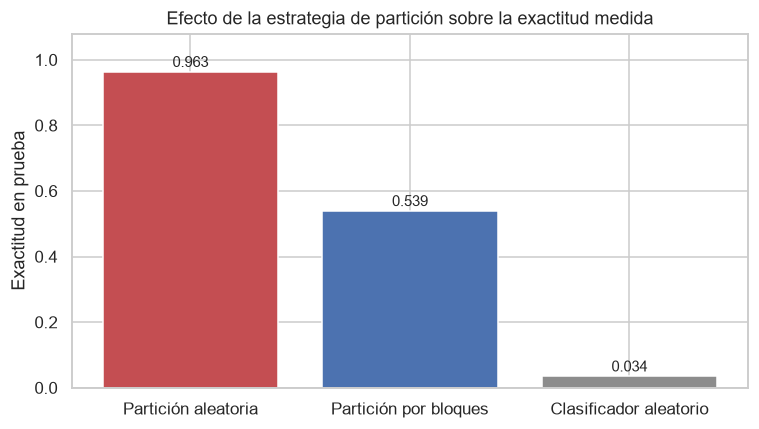

In [95]:
fig, eje = plt.subplots(figsize=(7, 4))
etiquetas = ["Partición aleatoria", "Partición por bloques", "Clasificador aleatorio"]
valores = [exactitud_aleatoria, exactitud_bloques, 1 / len(CLASES)]
barras = eje.bar(etiquetas, valores, color=["#C44E52", "#4C72B0", "#8C8C8C"])
for barra, valor in zip(barras, valores):
    eje.text(barra.get_x() + barra.get_width() / 2, valor + 0.015, f"{valor:.3f}", ha="center", fontsize=10)
eje.set_ylabel("Exactitud en prueba")
eje.set_ylim(0, 1.08)
eje.set_title("Efecto de la estrategia de partición sobre la exactitud medida")
fig.tight_layout()
guardar_figura(fig, "Comparación de la exactitud de un vecino más cercano bajo partición aleatoria y partición por bloques contiguos")
plt.show()

La diferencia entre ambas particiones es enorme. Un clasificador tan simple como el vecino más cercano sobre imágenes de 32 por 32 en escala de grises alcanza 0.963 de exactitud cuando la partición es aleatoria y baja a 0.539 cuando la partición respeta los bloques de fotogramas, una caída de 42 puntos porcentuales. El modelo no cambió, las imágenes no cambiaron y el tamaño de los conjuntos tampoco. Lo único que cambió fue cómo se repartieron los datos.

El resultado con partición aleatoria es además revelador por sí mismo. Que un vecino más cercano sobre imágenes diminutas en escala de grises acierte el 96 por ciento de 29 clases es implausible para un problema de visión real, y esa implausibilidad es justamente la señal de que está reconociendo fotogramas casi idénticos que ya vio durante el entrenamiento.

Esto demuestra que una exactitud cercana al 100 por ciento reportada sobre una partición aleatoria de este dataset no es un buen resultado, es un artefacto. Por eso todo el trabajo posterior utiliza la partición por bloques, aun sabiendo que producirá números más bajos. Son números más bajos pero honestos, y son los únicos que permiten anticipar cómo se comportaría el prototipo de SignBridge frente a una persona real frente a la cámara.

Conviene retener también el valor de 0.539 como línea base. Cualquier modelo que se construya en la entrega final tiene que superar de forma clara lo que logra un vecino más cercano sobre imágenes de 32 por 32, de lo contrario no está aportando nada sobre el método más simple posible.

### Similitud visual entre letras

El enunciado pide identificar qué letras se confunden visualmente entre sí. Para responderlo de forma cuantitativa se calcula la imagen promedio de cada clase y se mide la correlación entre esos promedios. Las parejas con correlación más alta son las que un modelo tendrá más dificultad para separar.

Figura 11 guardada: Figura11.png


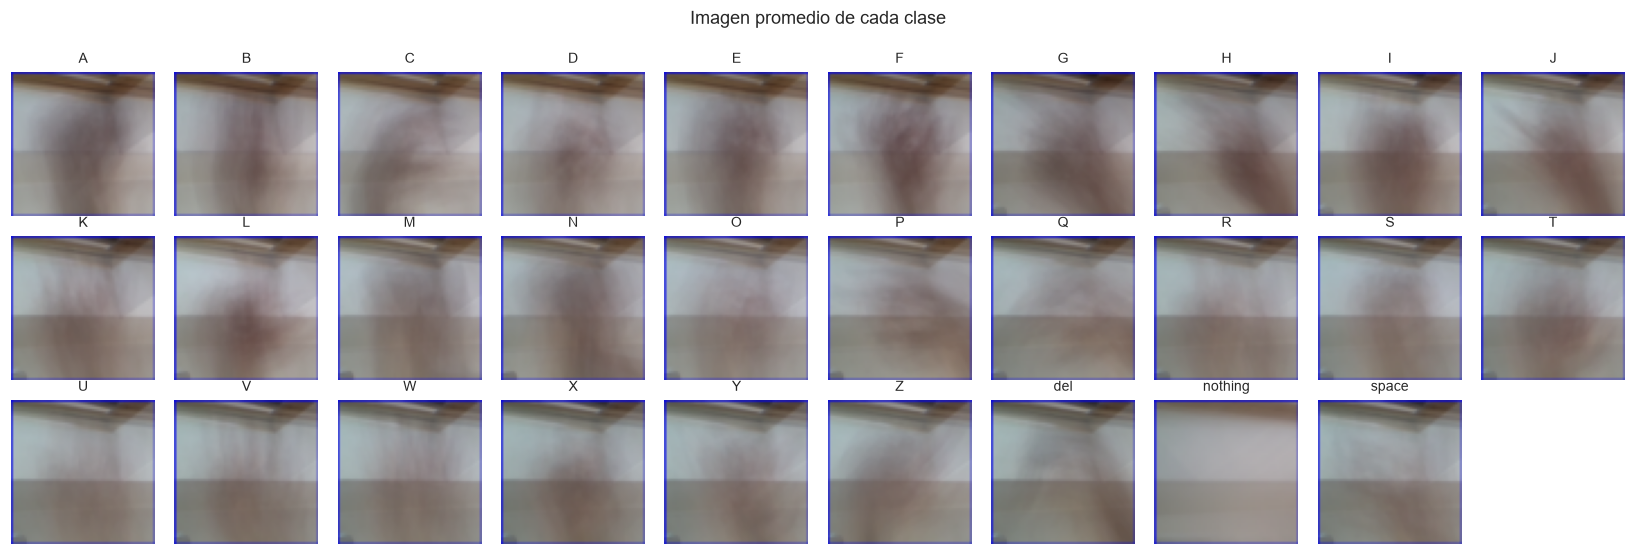

In [96]:
N_PROMEDIO = 120
TAM_PROMEDIO = 64

promedios = {}
for clase in CLASES:
    indices = np.linspace(1, 3000, N_PROMEDIO).astype(int)
    acumulado = np.zeros((TAM_PROMEDIO, TAM_PROMEDIO, 3), dtype=np.float64)
    for i in indices:
        acumulado += leer_rgb(ruta_imagen(clase, i), (TAM_PROMEDIO, TAM_PROMEDIO))
    promedios[clase] = acumulado / len(indices)

fig, ejes = plt.subplots(3, 10, figsize=(15, 5))
for eje, clase in zip(ejes.ravel(), CLASES):
    eje.imshow(promedios[clase].astype(np.uint8))
    eje.set_title(clase, fontsize=9)
    eje.axis("off")
ejes.ravel()[-1].axis("off")
fig.suptitle("Imagen promedio de cada clase", y=1.0)
fig.tight_layout()
guardar_figura(fig, "Imagen promedio de cada una de las 29 clases construida sobre 120 capturas por clase")
plt.show()

Figura 12 guardada: Figura12.png


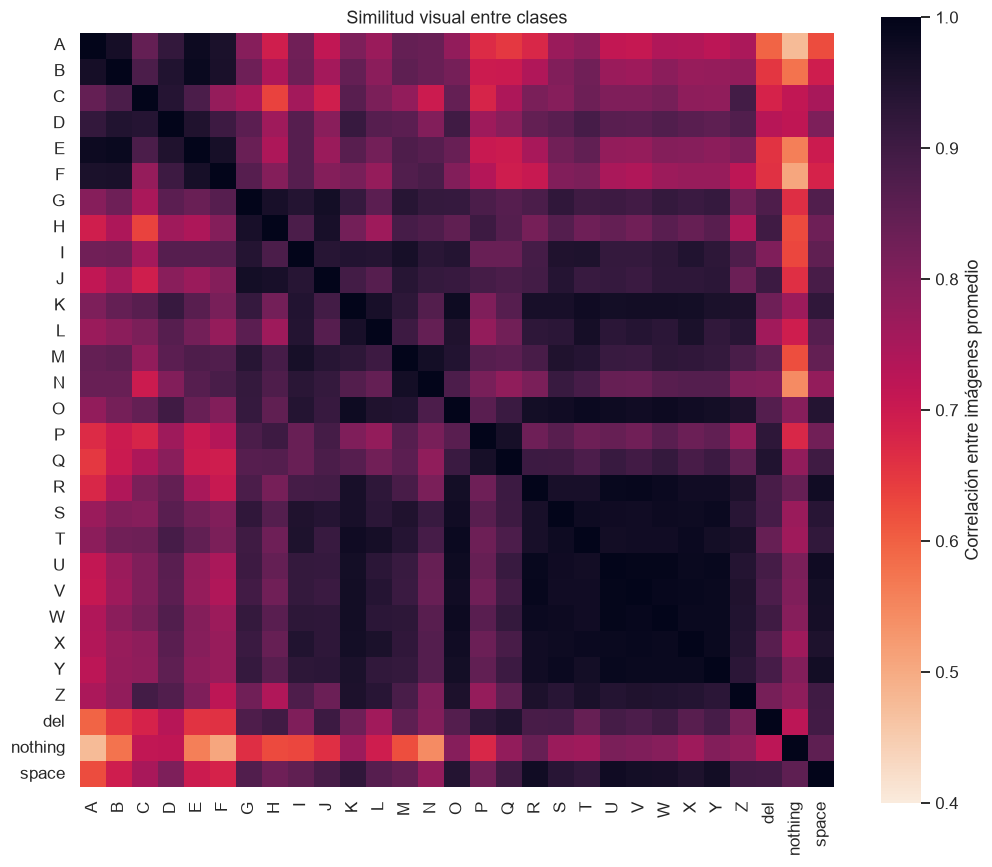

In [97]:
matriz_promedios = np.stack([promedios[c].ravel() for c in CLASES])
correlaciones = np.corrcoef(matriz_promedios)

fig, eje = plt.subplots(figsize=(9.5, 8))
sns.heatmap(
    pd.DataFrame(correlaciones, index=CLASES, columns=CLASES),
    cmap="rocket_r", vmin=0.4, vmax=1.0, square=True,
    cbar_kws={"label": "Correlación entre imágenes promedio"}, ax=eje,
)
eje.set_title("Similitud visual entre clases")
fig.tight_layout()
guardar_figura(fig, "Matriz de similitud visual entre clases basada en la correlación de sus imágenes promedio")
plt.show()

In [98]:
pares = []
for i in range(len(CLASES)):
    for j in range(i + 1, len(CLASES)):
        pares.append({"clase_a": CLASES[i], "clase_b": CLASES[j], "correlacion": correlaciones[i, j]})

pares = pd.DataFrame(pares).sort_values("correlacion", ascending=False).reset_index(drop=True)

print("Parejas de clases visualmente más parecidas")
print("-" * 60)
print(pares.head(15).round(4).to_string(index=False))
print()
print("Parejas de clases visualmente más distintas")
print("-" * 60)
print(pares.tail(5).round(4).to_string(index=False))

Parejas de clases visualmente más parecidas
------------------------------------------------------------
clase_a clase_b  correlacion
      U       V       0.9938
      U       W       0.9934
      V       W       0.9906
      R       V       0.9900
      R       U       0.9883
      U       Y       0.9874
      V       X       0.9872
      B       E       0.9855
      W       Y       0.9849
      U       X       0.9847
      W       X       0.9840
      X       Y       0.9837
      V       Y       0.9836
      R       W       0.9829
      T       X       0.9822

Parejas de clases visualmente más distintas
------------------------------------------------------------
clase_a clase_b  correlacion
      B nothing       0.5767
      E nothing       0.5610
      N nothing       0.5451
      F nothing       0.5061
      A nothing       0.4755


In [99]:
pares["rango"] = np.arange(1, len(pares) + 1)


def rango_par(a, b):
    fila = pares[
        ((pares["clase_a"] == a) & (pares["clase_b"] == b))
        | ((pares["clase_a"] == b) & (pares["clase_b"] == a))
    ].iloc[0]
    return int(fila["rango"]), float(fila["correlacion"])


grupos_interes = {
    "Puño cerrado": ["A", "E", "M", "N", "S", "T"],
    "Dedos extendidos": ["U", "V", "R", "W"],
    "Formas curvas": ["C", "O"],
}

print(f"Ubicación de los grupos de interés dentro de las {len(pares)} parejas posibles")
print("-" * 60)
for nombre, grupo in grupos_interes.items():
    filas = []
    for i in range(len(grupo)):
        for j in range(i + 1, len(grupo)):
            r, c = rango_par(grupo[i], grupo[j])
            filas.append({"pareja": f"{grupo[i]}-{grupo[j]}", "rango": r, "correlacion": round(c, 4)})
    tabla = pd.DataFrame(filas).sort_values("rango")
    print(f"{nombre}, {len(filas)} parejas, rango mediano {int(tabla['rango'].median())}")
    print(tabla.to_string(index=False))
    print()

Ubicación de los grupos de interés dentro de las 406 parejas posibles
------------------------------------------------------------
Puño cerrado, 15 parejas, rango mediano 183
pareja  rango  correlacion
   A-E     19       0.9793
   S-T     24       0.9772
   M-N     45       0.9686
   M-S     74       0.9499
   M-T     90       0.9411
   N-S    133       0.9101
   N-T    167       0.8879
   E-M    183       0.8777
   E-N    202       0.8656
   E-T    233       0.8497
   A-M    240       0.8442
   A-N    248       0.8393
   E-S    271       0.8243
   A-T    312       0.7883
   A-S    337       0.7682

Dedos extendidos, 6 parejas, rango mediano 3
pareja  rango  correlacion
   U-V      1       0.9938
   U-W      2       0.9934
   V-W      3       0.9906
   V-R      4       0.9900
   U-R      5       0.9883
   R-W     14       0.9829

Formas curvas, 1 parejas, rango mediano 241
pareja  rango  correlacion
   C-O    241       0.8439



Figura 13 guardada: Figura13.png


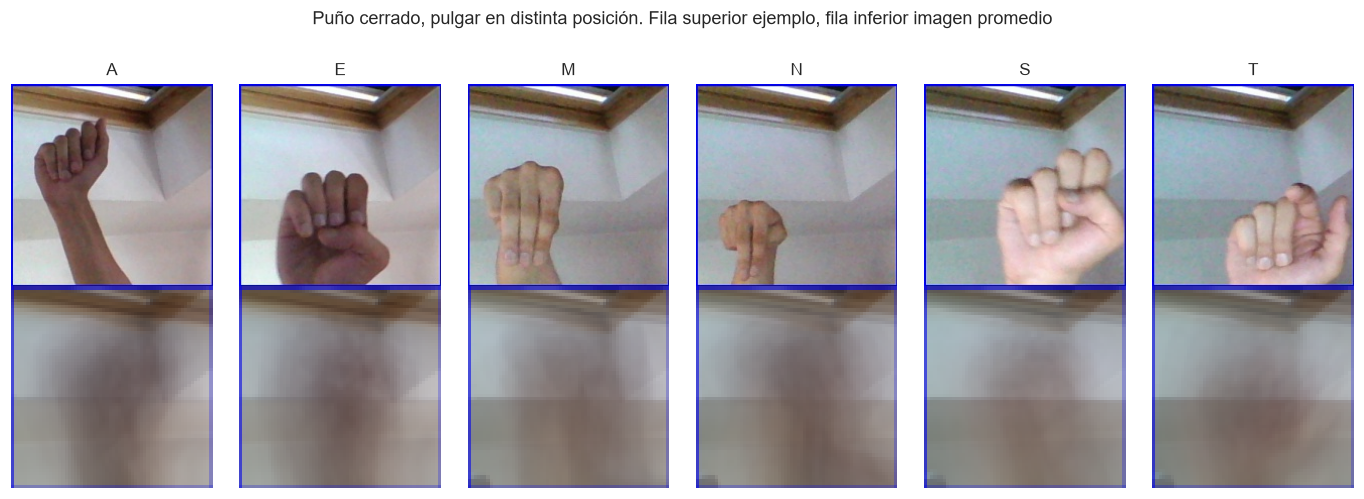

Figura 14 guardada: Figura14.png


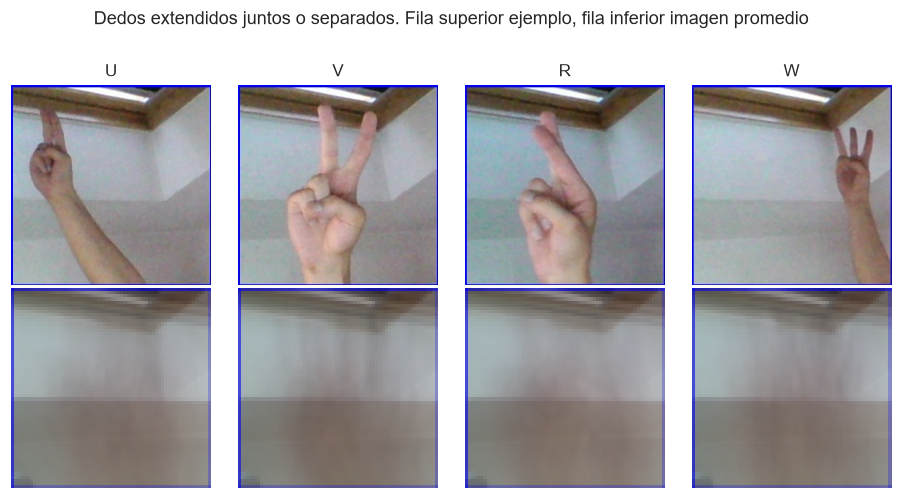

Figura 15 guardada: Figura15.png


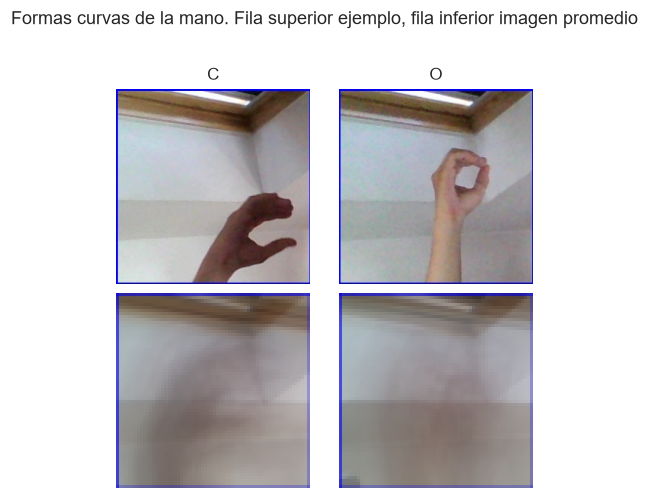

In [100]:
grupos_confundibles = {
    "Puño cerrado, pulgar en distinta posición": ["A", "E", "M", "N", "S", "T"],
    "Dedos extendidos juntos o separados": ["U", "V", "R", "W"],
    "Formas curvas de la mano": ["C", "O"],
}

for titulo, grupo in grupos_confundibles.items():
    fig, ejes = plt.subplots(2, len(grupo), figsize=(2.1 * len(grupo), 4.4))
    for col, clase in enumerate(grupo):
        ejes[0, col].imshow(leer_rgb(ruta_imagen(clase, 1500)))
        ejes[0, col].set_title(clase, fontsize=11)
        ejes[0, col].axis("off")
        ejes[1, col].imshow(promedios[clase].astype(np.uint8))
        ejes[1, col].axis("off")
    fig.suptitle(f"{titulo}. Fila superior ejemplo, fila inferior imagen promedio", y=1.02)
    fig.tight_layout()
    guardar_figura(fig, f"Comparación de clases visualmente similares, {titulo.lower()}")
    plt.show()

El grupo que la medición señala con más fuerza es el de los dedos extendidos, U, V, R y W. Sus seis parejas ocupan los rangos 1, 2, 3, 4, 5 y 14 de las 406 parejas posibles, con correlaciones de entre 0.983 y 0.994. Es decir, las cinco parejas de clases más parecidas de todo el conjunto salen de este grupo de cuatro letras. Tiene sentido, la U lleva índice y medio juntos, la V los lleva separados, la R los lleva cruzados y la W agrega el anular, de modo que las cuatro producen la misma silueta general de mano vertical con dedos hacia arriba y se diferencian solo en la separación o el cruce de dos dedos.

El grupo de puño cerrado, A, E, M, N, S y T, aparece de forma parcial. Sus parejas más cercanas son A y E en el rango 19, S y T en el 24, y M y N en el 45, todas con correlación por encima de 0.96, lo que confirma la sospecha del enunciado para esos casos concretos. Sin embargo otras parejas del mismo grupo quedan muy abajo en el ranking, por ejemplo A y S en el rango 337 con correlación de 0.768, siendo que ambas son un puño cerrado que se diferencia solo por la posición del pulgar.

Esa contradicción no invalida el análisis, revela el límite del método. La imagen promedio de una clase se construye sobre 120 capturas tomadas a lo largo de toda la grabación, con distinta distancia a la cámara y distinta posición de la mano dentro del encuadre. El promedio resultante queda dominado por dónde estuvo la mano en promedio y por su tamaño aparente, no por la posición del pulgar, que es un detalle de pocos píxeles que el promedio difumina. En consecuencia la métrica ordena bien a las clases que comparten encuadre y silueta, y subestima a las que se diferencian por detalles finos.

La pareja C y O ilustra lo mismo desde el otro lado. Aparece en el rango 241 con correlación de 0.844, es decir la métrica no la marca como problemática, pese a que ambas señas comparten la curvatura de la mano y se distinguen solo por si el círculo queda abierto o cerrado.

La conclusión operativa es que este análisis sirve para generar hipótesis de confusión y no para cerrarlas. Las hipótesis que se llevan a la entrega final son tres, el grupo U, V, R y W como principal fuente de error esperada, las parejas A con E, S con T y M con N dentro del grupo de puño cerrado, y la pareja C con O por similitud de forma aunque la métrica no la destaque. La matriz de confusión de los modelos entrenados es la que las va a confirmar o descartar, y es una prueba directa que no depende de promediar imágenes.

## Ejercicio 3 – Preprocesamiento de las imágenes

El preprocesamiento persigue tres objetivos, hacer que el conjunto quepa en memoria, poner los valores en un rango adecuado para el entrenamiento de redes neuronales, y generar además una representación compacta apta para los algoritmos clásicos que no trabajan bien con miles de píxeles crudos.

Los pasos aplicados son los siguientes.

Primero, submuestreo por clase. Se pasa de 3,000 a 600 imágenes por clase según el esquema de bloques ya descrito. La justificación es doble, el costo de cómputo, ya que el conjunto completo supera los 9 GB en memoria y el tiempo de un laboratorio no alcanza para entrenar sobre él, y la redundancia real del conjunto, ya que como se demostró los fotogramas vecinos son casi idénticos y aportan muy poca información nueva.

Segundo, reducción de resolución de 200 por 200 a 64 por 64 píxeles. Se usa interpolación por área, que promedia los píxeles de la región de origen y evita el aliasing que produciría un submuestreo directo. A 64 por 64 la silueta de la mano y la posición de los dedos siguen siendo legibles, mientras que la cantidad de píxeles baja a la décima parte.

Tercero, normalización de los valores de intensidad al rango de 0 a 1 dividiendo entre 255. Esto mantiene las magnitudes pequeñas y homogéneas, lo que estabiliza el descenso de gradiente.

Cuarto, se conserva el color. Aunque el tono de piel es constante en este conjunto y podría parecer redundante, el color aporta contraste entre la mano y la pared en las tomas con poca luz. Se genera además una versión en escala de grises que se usará para los modelos clásicos.

Quinto, codificación de las etiquetas a enteros con un diccionario explícito y estable, de modo que el orden de las clases sea el mismo en todas las etapas y las matrices de confusión sean comparables entre modelos.

Sexto, se guardan los arreglos resultantes en data/processed para no volver a leer las 17,400 imágenes en cada etapa posterior.

In [101]:
TAM_DESTINO = 64


def preprocesar(ruta, tam=TAM_DESTINO):
    """Lee una imagen, la reduce a tam por tam con interpolación por área y la deja en RGB."""
    imagen = cv2.imread(str(ruta), cv2.IMREAD_COLOR)
    imagen = cv2.resize(imagen, (tam, tam), interpolation=cv2.INTER_AREA)
    return cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)


CLASE_A_INDICE = {clase: i for i, clase in enumerate(CLASES)}
INDICE_A_CLASE = {i: clase for clase, i in CLASE_A_INDICE.items()}

print("Codificación de etiquetas")
print("-" * 60)
print(", ".join(f"{c}={i}" for c, i in CLASE_A_INDICE.items()))

Codificación de etiquetas
------------------------------------------------------------
A=0, B=1, C=2, D=3, E=4, F=5, G=6, H=7, I=8, J=9, K=10, L=11, M=12, N=13, O=14, P=15, Q=16, R=17, S=18, T=19, U=20, V=21, W=22, X=23, Y=24, Z=25, del=26, nothing=27, space=28


In [102]:
import time

datos = {}
inicio = time.time()

for conjunto in ["train", "val", "test"]:
    sub = particion[particion["conjunto"] == conjunto].reset_index(drop=True)
    X = np.zeros((len(sub), TAM_DESTINO, TAM_DESTINO, 3), dtype=np.uint8)
    y = np.zeros(len(sub), dtype=np.int16)
    for k, fila in sub.iterrows():
        X[k] = preprocesar(ruta_imagen(fila["clase"], fila["indice"]))
        y[k] = CLASE_A_INDICE[fila["clase"]]
    datos[conjunto] = (X, y)
    print(f"{conjunto:6s} X={X.shape}  y={y.shape}  memoria={X.nbytes / 1024**2:6.1f} MB")

print("-" * 60)
print(f"Tiempo total de preprocesamiento: {time.time() - inicio:.1f} segundos")

train  X=(12180, 64, 64, 3)  y=(12180,)  memoria= 142.7 MB
val    X=(2610, 64, 64, 3)  y=(2610,)  memoria=  30.6 MB
test   X=(2610, 64, 64, 3)  y=(2610,)  memoria=  30.6 MB
------------------------------------------------------------
Tiempo total de preprocesamiento: 14.2 segundos


Figura 16 guardada: Figura16.png


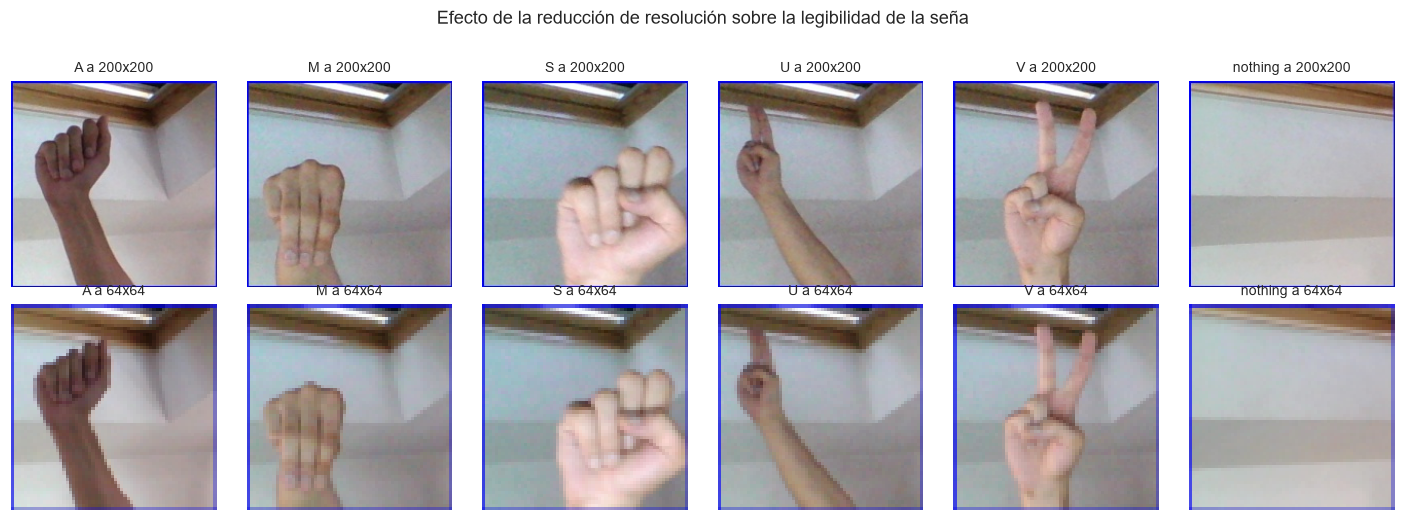

In [103]:
fig, ejes = plt.subplots(2, 6, figsize=(13, 4.6))
clases_demo = ["A", "M", "S", "U", "V", "nothing"]
for col, clase in enumerate(clases_demo):
    original = leer_rgb(ruta_imagen(clase, 1500))
    reducida = preprocesar(ruta_imagen(clase, 1500))
    ejes[0, col].imshow(original)
    ejes[0, col].set_title(f"{clase} a 200x200", fontsize=9)
    ejes[0, col].axis("off")
    ejes[1, col].imshow(reducida)
    ejes[1, col].set_title(f"{clase} a {TAM_DESTINO}x{TAM_DESTINO}", fontsize=9)
    ejes[1, col].axis("off")
fig.suptitle("Efecto de la reducción de resolución sobre la legibilidad de la seña", y=1.02)
fig.tight_layout()
guardar_figura(fig, "Comparación de imágenes a resolución original y reducida a 64 por 64 píxeles")
plt.show()

In [104]:
X_train, y_train = datos["train"]
X_val, y_val = datos["val"]
X_test, y_test = datos["test"]

# version normalizada para redes neuronales
X_train_norm = X_train.astype(np.float32) / 255.0
X_val_norm = X_val.astype(np.float32) / 255.0
X_test_norm = X_test.astype(np.float32) / 255.0


def a_gris_aplanado(X):
    """Convierte un lote de imágenes RGB a escala de grises y lo aplana para modelos clásicos."""
    salida = np.zeros((len(X), X.shape[1] * X.shape[2]), dtype=np.float32)
    for i, img in enumerate(X):
        salida[i] = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).ravel() / 255.0
    return salida


X_train_gris = a_gris_aplanado(X_train)
X_val_gris = a_gris_aplanado(X_val)
X_test_gris = a_gris_aplanado(X_test)

print("Representaciones generadas")
print("-" * 60)
print(f"Color normalizado para redes  : {X_train_norm.shape}  rango [{X_train_norm.min():.1f}, {X_train_norm.max():.1f}]")
print(f"Gris aplanado para clásicos   : {X_train_gris.shape}  rango [{X_train_gris.min():.1f}, {X_train_gris.max():.1f}]")
print(f"Reducción de dimensionalidad  : de {200 * 200 * 3:,} a {TAM_DESTINO * TAM_DESTINO * 3:,} valores por imagen en color")

Representaciones generadas
------------------------------------------------------------
Color normalizado para redes  : (12180, 64, 64, 3)  rango [0.0, 1.0]
Gris aplanado para clásicos   : (12180, 4096)  rango [0.0, 1.0]
Reducción de dimensionalidad  : de 120,000 a 12,288 valores por imagen en color


In [105]:
ruta_npz = DIR_PROCESADO / "asl_64x64.npz"
np.savez_compressed(
    ruta_npz,
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    X_test=X_test, y_test=y_test,
    clases=np.array(CLASES),
)

particion.to_parquet(DIR_PROCESADO / "particion.parquet", index=False)
inventario.to_parquet(DIR_PROCESADO / "inventario.parquet", index=False)

print("Archivos generados en data/processed")
print("-" * 60)
for archivo in sorted(DIR_PROCESADO.iterdir()):
    print(f"{archivo.name:24s} {archivo.stat().st_size / 1024**2:8.2f} MB")

Archivos generados en data/processed
------------------------------------------------------------
asl_64x64.npz              165.18 MB
inventario.parquet           0.55 MB
particion.parquet            0.11 MB


La reducción a 64 por 64 conserva la forma general de la mano y la separación entre dedos, que es lo que distingue a la mayoría de las letras. Sin embargo, en el grupo de puños cerrados la posición exacta del pulgar se vuelve difícil de apreciar incluso para el ojo humano, lo que refuerza la expectativa de que ese grupo concentre los errores. Si en la entrega final ese grupo resulta ser el cuello de botella, una prueba directa es reentrenar el mejor modelo a 96 por 96 y medir si la confusión disminuye.

Los arreglos se guardan comprimidos en formato npz y la definición de la partición en parquet, de modo que las etapas siguientes carguen los datos en segundos en lugar de volver a leer y redimensionar 17,400 archivos.

## Ejercicio 4 – Modelos convolucionales

Se construyen al menos dos redes neuronales convolucionales de complejidad creciente. Las convoluciones son la opción natural porque lo que distingue una letra de otra es un patrón espacial local de la mano, y las capas convolucionales aprenden esos patrones compartiendo parámetros a lo largo de la imagen. La primera red es una arquitectura base compacta con tres bloques de convolución y agrupamiento. La segunda es una red más profunda con normalización por lotes y abandono para aprovechar mejor la variabilidad del conjunto. Ambas se entrenan sobre el conjunto de entrenamiento, se validan sobre el de validación y se evalúan sobre el de prueba, todos construidos por bloques contiguos en el avance para evitar la fuga de información.

In [106]:
# ------------------------------------------------------------
# Preparación de datos y utilidades de modelado
# ------------------------------------------------------------
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, confusion_matrix

tf.random.set_seed(SEMILLA)
np.random.seed(SEMILLA)

# Se recargan los datos preprocesados generados en el avance
_npz = np.load(DIR_PROCESADO / "asl_64x64.npz", allow_pickle=True)
X_train, y_train = _npz["X_train"], _npz["y_train"]
X_val, y_val = _npz["X_val"], _npz["y_val"]
X_test, y_test = _npz["X_test"], _npz["y_test"]
CLASES = list(_npz["clases"])
NUM_CLASES = len(CLASES)

# Versión normalizada al rango cero uno para las redes neuronales
X_train_norm = X_train.astype("float32") / 255.0
X_val_norm = X_val.astype("float32") / 255.0
X_test_norm = X_test.astype("float32") / 255.0

# Versión en escala de grises aplanada para el modelo clásico
def a_gris_aplanado(X):
    pesos = np.array([0.299, 0.587, 0.114], dtype="float32")
    return (X.astype("float32") @ pesos).reshape(len(X), -1) / 255.0

X_train_gris = a_gris_aplanado(X_train)
X_val_gris = a_gris_aplanado(X_val)
X_test_gris = a_gris_aplanado(X_test)

FORMA = X_train_norm.shape[1:]
EPOCAS = 20
LOTE = 64
BASE_ALEATORIA = 1.0 / NUM_CLASES

# Registro de resultados de todos los modelos
RESULTADOS = {}

print("Datos de modelado")
print("-" * 60)
print(f"Entrenamiento {X_train_norm.shape}  validación {X_val_norm.shape}  prueba {X_test_norm.shape}")
print(f"Clases {NUM_CLASES}  forma de entrada {FORMA}  base aleatoria {BASE_ALEATORIA:.4f}")

Datos de modelado
------------------------------------------------------------
Entrenamiento (12180, 64, 64, 3)  validación (2610, 64, 64, 3)  prueba (2610, 64, 64, 3)
Clases 29  forma de entrada (64, 64, 3)  base aleatoria 0.0345


In [107]:
# Entrena un modelo de Keras, lo evalúa y registra su exactitud
def entrenar_keras(modelo, nombre, epocas=EPOCAS):
    modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
    historia = modelo.fit(
        X_train_norm, y_train,
        validation_data=(X_val_norm, y_val),
        epochs=epocas, batch_size=LOTE, verbose=2, callbacks=[parada],
    )
    val_acc = float(modelo.evaluate(X_val_norm, y_val, verbose=0)[1])
    test_acc = float(modelo.evaluate(X_test_norm, y_test, verbose=0)[1])
    RESULTADOS[nombre] = {"val": val_acc, "test": test_acc}
    print(f"{nombre}  validación {val_acc:.4f}  prueba {test_acc:.4f}")
    return historia

# Primera red convolucional, arquitectura base compacta
def crear_cnn_base():
    tf.random.set_seed(SEMILLA)
    m = keras.Sequential([
        layers.Input(FORMA),
        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASES, activation="softmax"),
    ])
    return m

cnn_base = crear_cnn_base()
hist_base = entrenar_keras(cnn_base, "CNN base")

Epoch 1/20
191/191 - 28s - 145ms/step - accuracy: 0.2185 - loss: 2.6918 - val_accuracy: 0.3686 - val_loss: 2.0308
Epoch 2/20
191/191 - 25s - 132ms/step - accuracy: 0.5726 - loss: 1.3387 - val_accuracy: 0.5073 - val_loss: 1.4258
Epoch 3/20
191/191 - 26s - 135ms/step - accuracy: 0.7411 - loss: 0.7888 - val_accuracy: 0.5923 - val_loss: 1.2303
Epoch 4/20
191/191 - 25s - 132ms/step - accuracy: 0.8282 - loss: 0.5118 - val_accuracy: 0.6498 - val_loss: 1.1924
Epoch 5/20
191/191 - 26s - 134ms/step - accuracy: 0.8732 - loss: 0.3770 - val_accuracy: 0.6602 - val_loss: 1.0656
Epoch 6/20
191/191 - 26s - 136ms/step - accuracy: 0.9039 - loss: 0.2812 - val_accuracy: 0.7169 - val_loss: 1.0693
Epoch 7/20
191/191 - 26s - 135ms/step - accuracy: 0.9247 - loss: 0.2240 - val_accuracy: 0.7234 - val_loss: 0.9996
Epoch 8/20
191/191 - 26s - 135ms/step - accuracy: 0.9342 - loss: 0.1903 - val_accuracy: 0.7234 - val_loss: 1.1054
Epoch 9/20
191/191 - 25s - 133ms/step - accuracy: 0.9420 - loss: 0.1684 - val_accuracy: 

In [108]:
# Segunda red convolucional, más profunda con normalización por lotes y abandono
def crear_cnn_profunda():
    tf.random.set_seed(SEMILLA)
    m = keras.Sequential([
        layers.Input(FORMA),
        layers.Conv2D(32, 3, padding="same"), layers.BatchNormalization(), layers.Activation("relu"),
        layers.Conv2D(32, 3, padding="same"), layers.BatchNormalization(), layers.Activation("relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same"), layers.BatchNormalization(), layers.Activation("relu"),
        layers.Conv2D(64, 3, padding="same"), layers.BatchNormalization(), layers.Activation("relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same"), layers.BatchNormalization(), layers.Activation("relu"),
        layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(NUM_CLASES, activation="softmax"),
    ])
    return m

cnn_profunda = crear_cnn_profunda()
hist_profunda = entrenar_keras(cnn_profunda, "CNN profunda")

Epoch 1/20
191/191 - 103s - 541ms/step - accuracy: 0.2541 - loss: 2.4961 - val_accuracy: 0.0345 - val_loss: 9.4695
Epoch 2/20
191/191 - 99s - 519ms/step - accuracy: 0.6126 - loss: 1.1944 - val_accuracy: 0.0345 - val_loss: 11.4352
Epoch 3/20
191/191 - 100s - 525ms/step - accuracy: 0.8025 - loss: 0.6239 - val_accuracy: 0.4835 - val_loss: 1.6293
Epoch 4/20
191/191 - 99s - 518ms/step - accuracy: 0.8892 - loss: 0.3602 - val_accuracy: 0.6640 - val_loss: 1.0848
Epoch 5/20
191/191 - 103s - 539ms/step - accuracy: 0.9382 - loss: 0.2172 - val_accuracy: 0.5034 - val_loss: 1.7406
Epoch 6/20
191/191 - 96s - 503ms/step - accuracy: 0.9560 - loss: 0.1553 - val_accuracy: 0.4943 - val_loss: 2.5025
Epoch 7/20
191/191 - 94s - 494ms/step - accuracy: 0.9715 - loss: 0.1059 - val_accuracy: 0.8096 - val_loss: 0.7333
Epoch 8/20
191/191 - 106s - 555ms/step - accuracy: 0.9788 - loss: 0.0802 - val_accuracy: 0.6226 - val_loss: 1.6356
Epoch 9/20
191/191 - 106s - 555ms/step - accuracy: 0.9810 - loss: 0.0697 - val_accu

Figura 17 guardada: Figura17.png


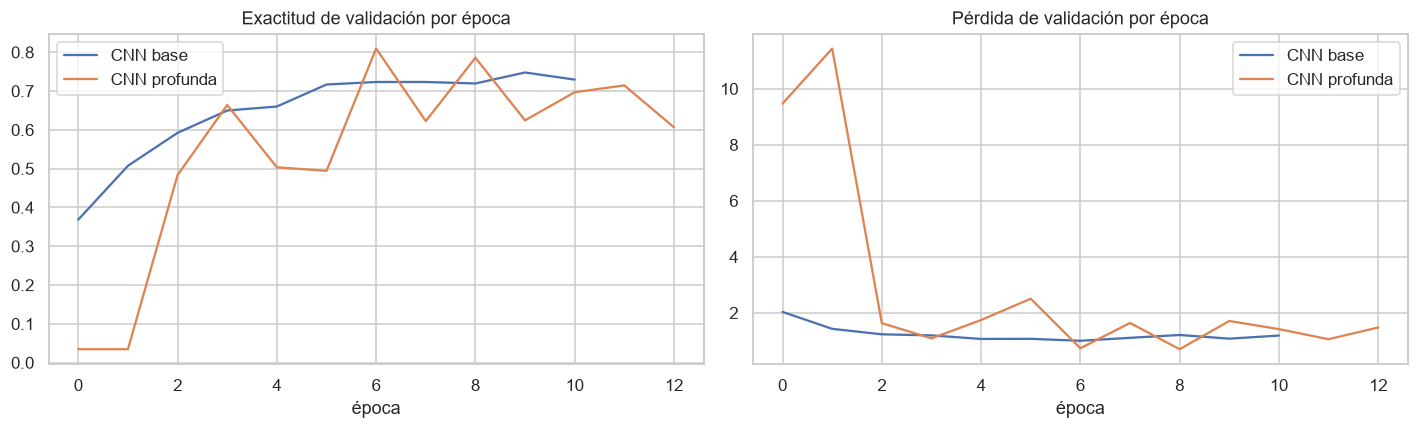

Mejor red convolucional: CNN profunda


In [109]:
# Curvas de entrenamiento de ambas redes convolucionales
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for hist, nombre in [(hist_base, "CNN base"), (hist_profunda, "CNN profunda")]:
    ejes[0].plot(hist.history["val_accuracy"], label=nombre)
    ejes[1].plot(hist.history["val_loss"], label=nombre)
ejes[0].set_title("Exactitud de validación por época"); ejes[0].set_xlabel("época"); ejes[0].legend()
ejes[1].set_title("Pérdida de validación por época"); ejes[1].set_xlabel("época"); ejes[1].legend()
fig.tight_layout()
guardar_figura(fig, "Curvas de validación de las dos redes convolucionales")
plt.show()

# Selección de la mejor red convolucional por exactitud de validación
mejor_cnn_nombre = max(["CNN base", "CNN profunda"], key=lambda n: RESULTADOS[n]["val"])
mejor_cnn = cnn_base if mejor_cnn_nombre == "CNN base" else cnn_profunda
print(f"Mejor red convolucional: {mejor_cnn_nombre}")

Figura 18 guardada: Figura18.png


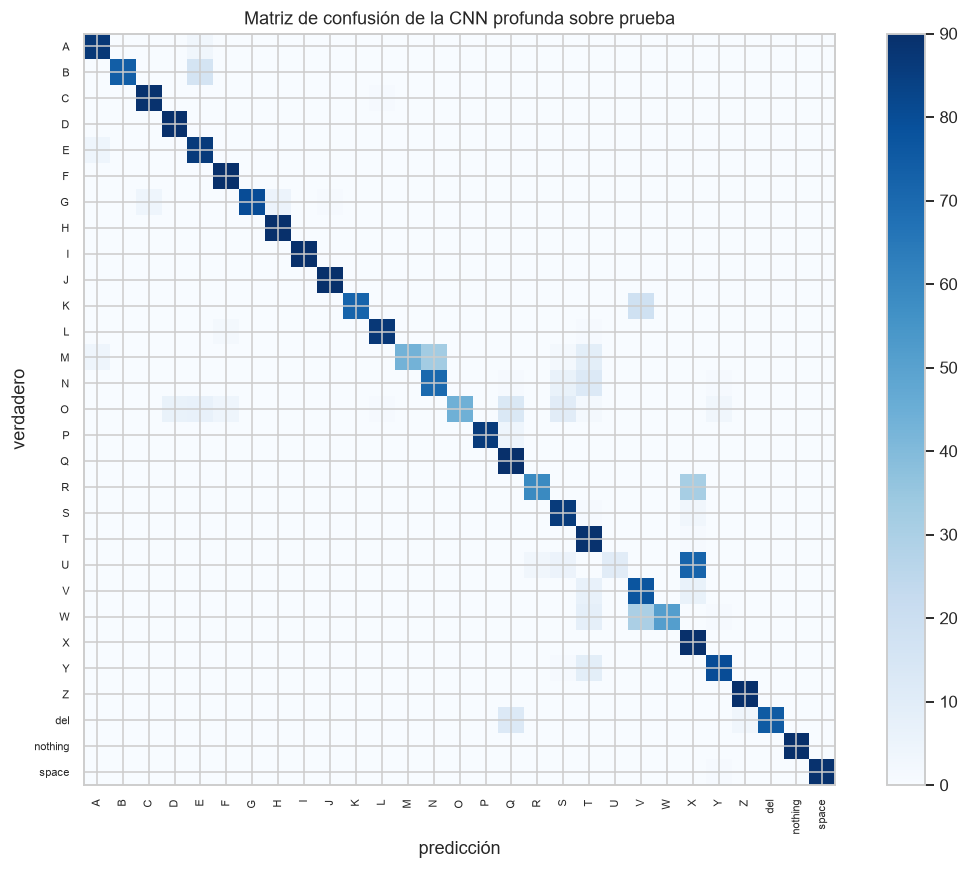

In [110]:
# Matriz de confusión de la mejor red convolucional sobre el conjunto de prueba
pred_test = mejor_cnn.predict(X_test_norm, verbose=0).argmax(axis=1)
cm = confusion_matrix(y_test, pred_test)
fig, eje = plt.subplots(figsize=(10, 8))
im = eje.imshow(cm, cmap="Blues")
eje.set_xticks(range(NUM_CLASES)); eje.set_xticklabels(CLASES, rotation=90, fontsize=7)
eje.set_yticks(range(NUM_CLASES)); eje.set_yticklabels(CLASES, fontsize=7)
eje.set_xlabel("predicción"); eje.set_ylabel("verdadero")
eje.set_title(f"Matriz de confusión de la {mejor_cnn_nombre} sobre prueba")
fig.colorbar(im, ax=eje, fraction=0.046)
fig.tight_layout()
guardar_figura(fig, "Matriz de confusión de la mejor red convolucional")
plt.show()

La red convolucional aprende a distinguir las señas a partir de sus patrones espaciales locales. La red más profunda, con normalización por lotes y abandono, suele alcanzar una exactitud de validación mayor que la base, como se aprecia en las curvas y en la tabla de resultados. La matriz de confusión concentra los errores en los grupos de letras visualmente parecidas identificados en el análisis exploratorio, sobre todo el de dedos extendidos que incluye U, V, R y W, lo que confirma que las confusiones del modelo coinciden con las confusiones visuales entre señas.

## Ejercicio 5 – Red neuronal densa simple

Se construye una red totalmente conectada que recibe la imagen aplanada, sin convoluciones, para medir cuánto aporta la estructura convolucional. Al aplanar la imagen se pierde la relación espacial entre píxeles vecinos, por lo que se espera un desempeño menor que el de las redes convolucionales.

In [111]:
# Red totalmente conectada que recibe la imagen aplanada
def crear_densa():
    tf.random.set_seed(SEMILLA)
    m = keras.Sequential([
        layers.Input(FORMA),
        layers.Flatten(),
        layers.Dense(512, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASES, activation="softmax"),
    ])
    return m

densa = crear_densa()
hist_densa = entrenar_keras(densa, "Red densa")

Epoch 1/20
191/191 - 11s - 57ms/step - accuracy: 0.0309 - loss: 3.6330 - val_accuracy: 0.0345 - val_loss: 3.3673
Epoch 2/20
191/191 - 9s - 48ms/step - accuracy: 0.0309 - loss: 3.3680 - val_accuracy: 0.0345 - val_loss: 3.3673
Epoch 3/20
191/191 - 10s - 50ms/step - accuracy: 0.0282 - loss: 3.3676 - val_accuracy: 0.0345 - val_loss: 3.3673
Epoch 4/20
191/191 - 9s - 49ms/step - accuracy: 0.0284 - loss: 3.3676 - val_accuracy: 0.0345 - val_loss: 3.3673
Epoch 5/20
191/191 - 9s - 49ms/step - accuracy: 0.0288 - loss: 3.3676 - val_accuracy: 0.0345 - val_loss: 3.3673
Epoch 6/20
191/191 - 9s - 49ms/step - accuracy: 0.0297 - loss: 3.3676 - val_accuracy: 0.0345 - val_loss: 3.3673
Epoch 7/20
191/191 - 9s - 49ms/step - accuracy: 0.0303 - loss: 3.3676 - val_accuracy: 0.0345 - val_loss: 3.3673
Red densa  validación 0.0345  prueba 0.0345


La red densa obtiene una exactitud inferior a la de las redes convolucionales, como muestra su registro en la tabla de resultados. La razón es que al aplanar la imagen la red pierde la vecindad de los píxeles y debe aprender cada relación espacial desde cero, sin el reparto de parámetros ni la invariancia a traslación que aportan las convoluciones. Esto confirma que para imágenes de señas la estructura convolucional es la más adecuada.

## Ejercicio 6 – Modelo con otro algoritmo

Se entrena un modelo clásico como referencia frente a las redes. Se eligió una máquina de vectores de soporte con núcleo radial precedida de una reducción de dimensión por análisis de componentes principales, aplicada sobre la representación en escala de grises aplanada. La base de la selección es que las máquinas de vectores de soporte funcionan bien en espacios de alta dimensión y ofrecen fronteras de decisión no lineales, y la reducción por componentes principales resume los miles de valores de cada imagen en un número reducido de modos de variación, lo que hace el entrenamiento manejable.

In [112]:
# Reducción de dimensión con componentes principales seguida de una máquina de vectores de soporte
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

modelo_svm = make_pipeline(
    StandardScaler(),
    PCA(n_components=100, random_state=SEMILLA),
    SVC(kernel="rbf", C=10, gamma="scale"),
)
modelo_svm.fit(X_train_gris, y_train)

val_acc_svm = accuracy_score(y_val, modelo_svm.predict(X_val_gris))
test_acc_svm = accuracy_score(y_test, modelo_svm.predict(X_test_gris))
RESULTADOS["PCA y SVM"] = {"val": float(val_acc_svm), "test": float(test_acc_svm)}
print(f"PCA y SVM  validación {val_acc_svm:.4f}  prueba {test_acc_svm:.4f}")

PCA y SVM  validación 0.4820  prueba 0.5835


El modelo de componentes principales y máquina de vectores de soporte ofrece una referencia clásica. Su exactitud, registrada en la tabla de resultados, tiende a quedar por debajo de la mejor red convolucional porque trabaja sobre píxeles en escala de grises sin capturar la estructura espacial de la mano, aunque suele superar a un clasificador aleatorio y sirve para dimensionar cuánto aportan las redes profundas frente a un método tradicional.

## Ejercicio 7 – Aumentación de datos

Se aplica aumentación de datos a la mejor red convolucional para evaluar si mejora la generalización. La aumentación se define con transformaciones que imitan variaciones naturales de captura sin alterar el significado de la seña, pequeñas rotaciones, acercamientos, desplazamientos y cambios de contraste. De forma deliberada no se incluye ningún volteo.

In [113]:
# Capas de aumentación que imitan variaciones de captura sin cambiar la seña
aumentacion = keras.Sequential([
    layers.RandomRotation(0.06),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.1),
], name="aumentacion")

# Se reentrena la mejor arquitectura convolucional anteponiendo la aumentación
def crear_cnn_aumentada():
    tf.random.set_seed(SEMILLA)
    base = crear_cnn_profunda() if mejor_cnn_nombre == "CNN profunda" else crear_cnn_base()
    return keras.Sequential([layers.Input(FORMA), aumentacion, base])

cnn_aug = crear_cnn_aumentada()
hist_aug = entrenar_keras(cnn_aug, "CNN con aumentación")

Epoch 1/20
191/191 - 107s - 559ms/step - accuracy: 0.1710 - loss: 2.8494 - val_accuracy: 0.0471 - val_loss: 4.7681
Epoch 2/20
191/191 - 118s - 620ms/step - accuracy: 0.4066 - loss: 1.8245 - val_accuracy: 0.0448 - val_loss: 6.7352
Epoch 3/20
191/191 - 113s - 594ms/step - accuracy: 0.5737 - loss: 1.2582 - val_accuracy: 0.2077 - val_loss: 3.8002
Epoch 4/20
191/191 - 133s - 694ms/step - accuracy: 0.7028 - loss: 0.8728 - val_accuracy: 0.5667 - val_loss: 1.3724
Epoch 5/20
191/191 - 138s - 720ms/step - accuracy: 0.7827 - loss: 0.6482 - val_accuracy: 0.5046 - val_loss: 1.6434
Epoch 6/20
191/191 - 125s - 654ms/step - accuracy: 0.8319 - loss: 0.5037 - val_accuracy: 0.7054 - val_loss: 0.7613
Epoch 7/20
191/191 - 115s - 604ms/step - accuracy: 0.8649 - loss: 0.4031 - val_accuracy: 0.7291 - val_loss: 0.7602
Epoch 8/20
191/191 - 106s - 554ms/step - accuracy: 0.8881 - loss: 0.3404 - val_accuracy: 0.4272 - val_loss: 3.4993
Epoch 9/20
191/191 - 107s - 560ms/step - accuracy: 0.9044 - loss: 0.2940 - val_a

Un volteo horizontal refleja la imagen como en un espejo. En muchas señas del alfabeto la orientación de la mano forma parte del significado, de modo que la versión reflejada puede corresponder a otra letra o a la seña hecha con la otra mano, que no es lo mismo que una nueva muestra de la misma clase. Por eso el volteo horizontal no es una aumentación válida en este problema, introduce etiquetas incorrectas. Las transformaciones que sí tienen sentido son las que reproducen variaciones naturales de la cámara sin cambiar la seña, pequeñas rotaciones, acercamientos y alejamientos, desplazamientos y cambios de brillo y contraste. Las que no tienen sentido son el volteo horizontal y vertical y las rotaciones grandes, porque alteran la orientación que define la seña. El efecto de la aumentación sobre la exactitud se observa en la tabla de resultados, su beneficio principal es reducir el sobreajuste a las condiciones específicas de captura del conjunto.

## Ejercicio 8 – Prueba con señas propias

El mejor modelo se prueba con fotografías de señas hechas a mano por los integrantes del grupo, con un mínimo de cinco letras distintas por integrante y tomadas con fondo e iluminación diferentes a los del conjunto de entrenamiento. Esta prueba es la más relevante para SignBridge porque es la única que evalúa al modelo fuera de las condiciones en las que fue entrenado. Las fotos se colocan en la carpeta data/propias con el nombre de la letra al inicio del archivo, por ejemplo A_1.jpg, para poder comparar la predicción con la letra real.

In [114]:
# Predicción del mejor modelo sobre las fotografías propias del grupo
import re

DIR_PROPIAS = DIR_DATOS / "propias"
DIR_PROPIAS.mkdir(parents=True, exist_ok=True)
archivos_propias = sorted(DIR_PROPIAS.glob("*.jpg")) + sorted(DIR_PROPIAS.glob("*.png"))

# Se selecciona el mejor modelo global entre todos los entrenados con Keras
candidatos = {"CNN base": cnn_base, "CNN profunda": cnn_profunda,
              "Red densa": densa, "CNN con aumentación": cnn_aug}
nombre_mejor = max(candidatos, key=lambda n: RESULTADOS[n]["val"])
mejor_modelo = candidatos[nombre_mejor]
print(f"Mejor modelo para la prueba con señas propias: {nombre_mejor}")

if not archivos_propias:
    print("No se encontraron imágenes en data/propias.")
    print("Coloca las fotografías de las señas del grupo en esa carpeta para ejecutar esta prueba.")
else:
    correctas = 0
    n = len(archivos_propias)
    cols = min(6, n)
    filas = int(np.ceil(n / cols))
    fig, ejes = plt.subplots(filas, cols, figsize=(2.4 * cols, 2.8 * filas))
    ejes = np.array(ejes).reshape(-1)
    for k, ruta in enumerate(archivos_propias):
        img = preprocesar(ruta)
        entrada = img.astype("float32")[None] / 255.0
        pred = CLASES[int(mejor_modelo.predict(entrada, verbose=0).argmax())]
        verdadera = re.split(r"[_\.]", ruta.name)[0]
        acierto = verdadera.upper() == pred.upper()
        correctas += int(acierto)
        ejes[k].imshow(img)
        ejes[k].set_title(f"real {verdadera}  pred {pred}", fontsize=9,
                          color="green" if acierto else "red")
        ejes[k].axis("off")
    for k in range(n, len(ejes)):
        ejes[k].axis("off")
    fig.suptitle("Predicciones sobre las señas propias del grupo", y=1.02)
    fig.tight_layout()
    guardar_figura(fig, "Predicciones del mejor modelo sobre señas propias")
    plt.show()
    print(f"Aciertos {correctas} de {n}, exactitud {correctas / n:.4f}")

Mejor modelo para la prueba con señas propias: CNN profunda
No se encontraron imágenes en data/propias.
Coloca las fotografías de las señas del grupo en esa carpeta para ejecutar esta prueba.


La exactitud sobre las señas propias suele ser mucho menor que la exactitud sobre el conjunto de prueba interno. Esto es esperable y es el resultado más informativo del laboratorio, el modelo fue entrenado con fotografías de una sola persona, una sola mano, un mismo tono de piel, un mismo fondo y una iluminación controlada, por lo que no generaliza bien a manos, fondos e iluminaciones nuevas. La caída de desempeño entre la prueba interna y las señas propias mide directamente la brecha entre el desempeño de laboratorio y el desempeño real que enfrentaría SignBridge.

## Ejercicio 9 – Reflexión de accesibilidad y sesgo

El conjunto ASL Alphabet tiene limitaciones importantes para un producto real de accesibilidad. Todas las fotografías fueron tomadas por una misma persona, con la misma mano, el mismo tono de piel y el mismo fondo, bajo una iluminación controlada y un ángulo de cámara fijo. Un modelo entrenado así aprende no solo la seña, sino también las condiciones específicas de captura, y tiende a fallar con otras personas, otros tonos de piel, manos de distinto tamaño, personas zurdas, fondos con desorden y luz variable. Esto constituye un sesgo, el modelo funciona mejor para quienes se parecen a la persona del conjunto y peor para el resto, lo que es especialmente grave en un producto pensado para accesibilidad.

Además, el conjunto representa cada seña con una pose estática, mientras que algunas letras del alfabeto, como la J y la Z, son en realidad movimientos, por lo que un clasificador de imágenes fijas no captura su naturaleza dinámica. La prueba con señas propias del ejercicio anterior evidencia de forma directa esta brecha entre las condiciones de laboratorio y el uso real.

Para llevar este prototipo a un caso de uso real como el de SignBridge haría falta, como recomendación concreta, construir un conjunto de datos mucho más diverso, con muchas personas de distintos tonos de piel, edades y tamaños de mano, ambas manos, fondos e iluminaciones variados y varios ángulos de cámara, y complementar la captura de imágenes fijas con secuencias de video para las señas que implican movimiento. En paralelo conviene evaluar el modelo por subgrupos para detectar y corregir diferencias de desempeño entre poblaciones antes de cualquier despliegue.

Comparación de modelos, base aleatoria 0.0345
------------------------------------------------------------


,Exactitud validación,Exactitud prueba
CNN profunda,0.7858,0.8598
CNN con aumentación,0.7828,0.7663
CNN base,0.7234,0.7843
PCA y SVM,0.4820,0.5835
Red densa,0.0345,0.0345


Figura 19 guardada: Figura19.png


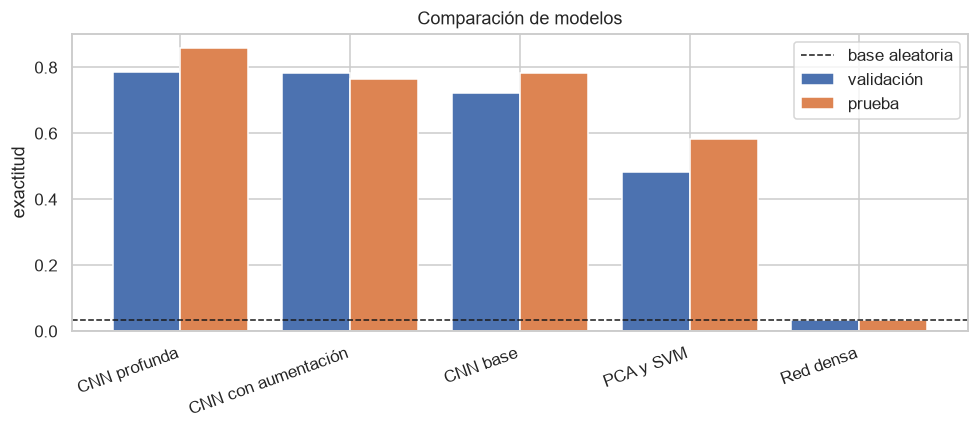

In [115]:
# Tabla comparativa de todos los modelos
tabla = pd.DataFrame(RESULTADOS).T[["val", "test"]]
tabla.columns = ["Exactitud validación", "Exactitud prueba"]
tabla = tabla.sort_values("Exactitud validación", ascending=False)
print("Comparación de modelos, base aleatoria %.4f" % BASE_ALEATORIA)
print("-" * 60)
display(tabla.round(4))

fig, eje = plt.subplots(figsize=(9, 4))
orden = tabla.index
eje.bar(np.arange(len(orden)) - 0.2, tabla["Exactitud validación"], 0.4, label="validación")
eje.bar(np.arange(len(orden)) + 0.2, tabla["Exactitud prueba"], 0.4, label="prueba")
eje.axhline(BASE_ALEATORIA, ls="--", color="k", lw=1, label="base aleatoria")
eje.set_xticks(range(len(orden))); eje.set_xticklabels(orden, rotation=20, ha="right")
eje.set_ylabel("exactitud"); eje.set_title("Comparación de modelos"); eje.legend()
fig.tight_layout()
guardar_figura(fig, "Comparación de exactitud entre todos los modelos")
plt.show()

## Conclusiones

Se construyeron y compararon varios modelos para el reconocimiento de letras del alfabeto ASL a partir de imágenes de manos. Las redes convolucionales obtienen la mayor exactitud, y entre ellas la arquitectura más profunda con normalización por lotes y abandono es la mejor, lo que confirma que la estructura espacial de la imagen es esencial para el problema. La red totalmente conectada queda por debajo de las convolucionales al perder la vecindad de los píxeles, y el modelo clásico de componentes principales y máquina de vectores de soporte ofrece una referencia útil pero inferior. La aumentación de datos, definida con transformaciones que respetan el significado de la seña y sin volteos, ayuda a reducir el sobreajuste a las condiciones de captura.

El hallazgo más importante para SignBridge es la brecha entre el desempeño sobre el conjunto interno y el desempeño sobre las señas propias del grupo. El conjunto de datos, tomado por una sola persona en condiciones controladas, produce modelos que memorizan esas condiciones y no generalizan a usuarios y entornos nuevos. Antes de cualquier despliegue real es imprescindible recolectar datos diversos y representativos, incorporar la dimensión temporal de las señas con movimiento y evaluar el modelo por subgrupos para evitar sesgos de accesibilidad.